# Safe to operate: constant loss rates (200k runs)

**Question.** For which ESC parameters does the controller converge to the ideal fuel ratio, and how fast?

**Data.** `STO-const_decay-200k.csv`, generated by `STO_ESC_constdecay.m`: 200,000 runs of 100 s with random ESC
parameters on the constant plant ($\tau_D = 1.71$ s, $\tau_T = 1.66$ s, so $r_\mathrm{ideal} \approx 0.507$).
The estimate $\hat r$ starts at 0.

## 1. Setup

In [1]:
# Shared tools (plot style, model constants, averaged-ESC formulas) live in Tools/ at the repository root
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'Tools' / 'esc_tools.py').exists())
sys.path.insert(0, str(ROOT / 'Tools'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import esc_tools as esc

esc.apply_style()   # one plot style for every notebook in this repository

In [2]:
df = pd.read_csv('STO-const_decay-200k.csv')
print(f'{len(df):,} runs, {df.shape[1]} columns')
df.head()

200,000 runs, 5 columns


,optimizer_gain,dither_amplitude,dither_frequency,converged,convergence_time
0,0.042251,0.769641,3.378739,1,56.96
1,0.000027,0.230726,2.047301,0,NaN
2,0.000936,0.178305,9.894319,0,NaN
3,0.000263,0.920066,5.168903,0,NaN
4,0.000135,0.815159,9.100947,0,NaN


## 2. Data overview

In [3]:
overview = pd.DataFrame({'type': df.dtypes.astype(str), 'missing': df.isna().sum(), 'min': df.min(), 'max': df.max()})
print('convergence_time is missing exactly for the runs that did not converge:',
      bool((df['convergence_time'].isna() == (df['converged'] == 0)).all()))
overview

convergence_time is missing exactly for the runs that did not converge: True


,type,missing,min,max
optimizer_gain,float64,0,0.000010,4.999927
dither_amplitude,float64,0,0.000003,0.999998
dither_frequency,float64,0,0.000065,9.999906
converged,int64,0,0.000000,1.000000
convergence_time,float64,126181,2.250000,95.010000


## 3. Convergence

#### Original plots

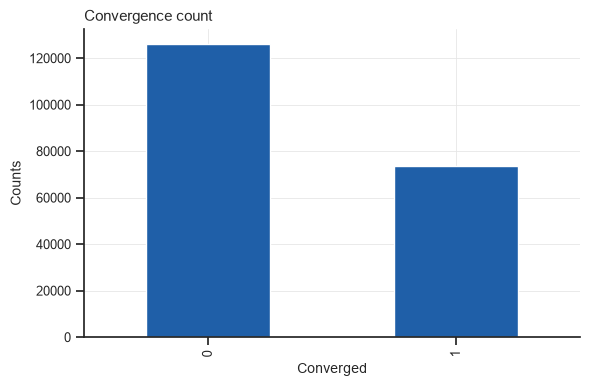

In [4]:
cv = df['converged'].value_counts().head(10).plot(kind = 'bar', title = 'Convergence count')

cv.set_xlabel('Converged')
cv.set_ylabel('Counts')
plt.show()

# Inspect the balance between converged and non-converged samples.

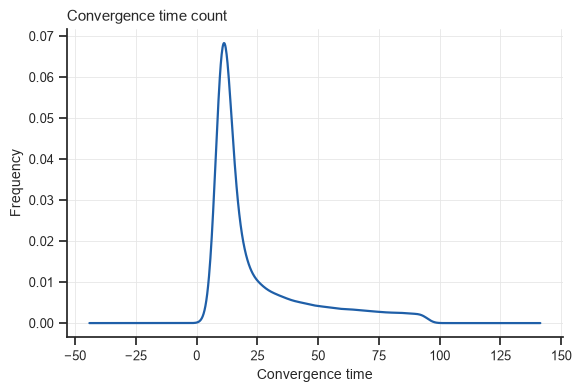

In [5]:
ct = df['convergence_time'].plot(kind = 'kde',
                title = 'Convergence time count')
ct.set_xlabel('Convergence time')
ct.set_ylabel('Frequency')
plt.show()

# Inspect the distribution of convergence times.

#### Added plots

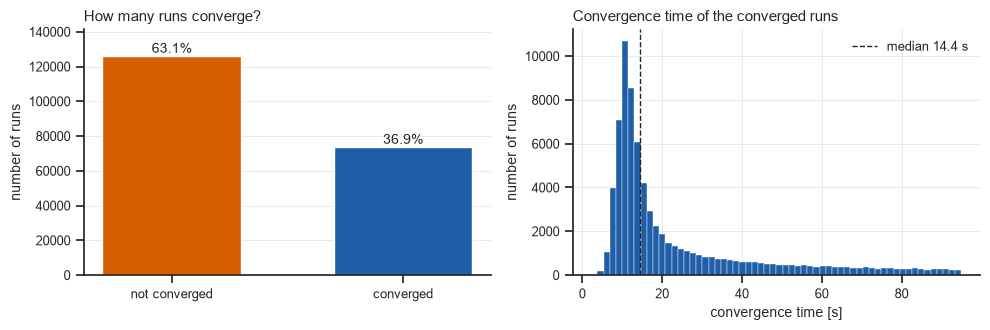

73,819 of 200,000 runs converge (36.9%).
Convergence time: median 14.4 s, fastest 2.25 s.
Runs that converge in under 10 s: 12,465
Runs that converge in under 5 s: 138


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
esc.outcome_bar(df['converged'], names=('not converged', 'converged'), title='How many runs converge?', ax=axes[0])
esc.time_hist(df['convergence_time'], title='Convergence time of the converged runs', ax=axes[1])
fig.tight_layout()
plt.show()

n_conv = int(df['converged'].sum())
print(f"{n_conv:,} of {len(df):,} runs converge ({n_conv / len(df):.1%}).")
print(f"Convergence time: median {df['convergence_time'].median():.1f} s, fastest {df['convergence_time'].min():.2f} s.")
for limit in (10, 5):
    print(f"Runs that converge in under {limit} s: {(df['convergence_time'] < limit).sum():,}")

## 4. Parameter relationships

### All converged runs

Only converged runs have a convergence time, so these plots show converged runs only.
The gain is drawn on a logarithmic axis because it was sampled log-uniformly.

#### Original plots

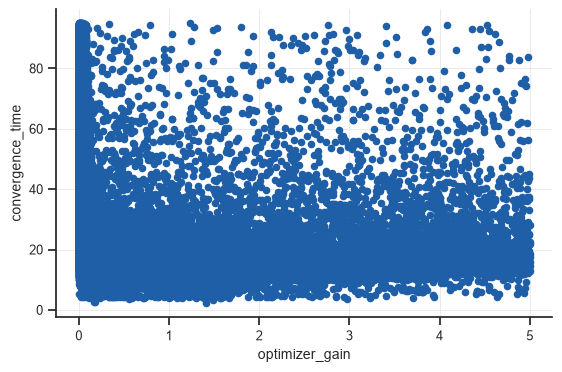

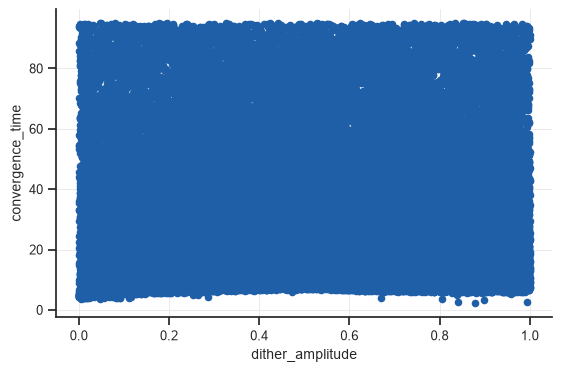

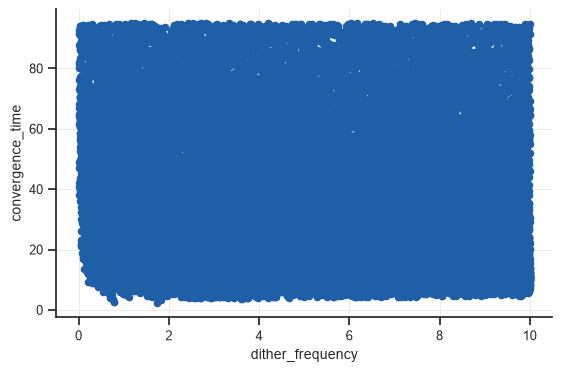

In [7]:
for i in range (df.shape[1] - 2):
    df.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()

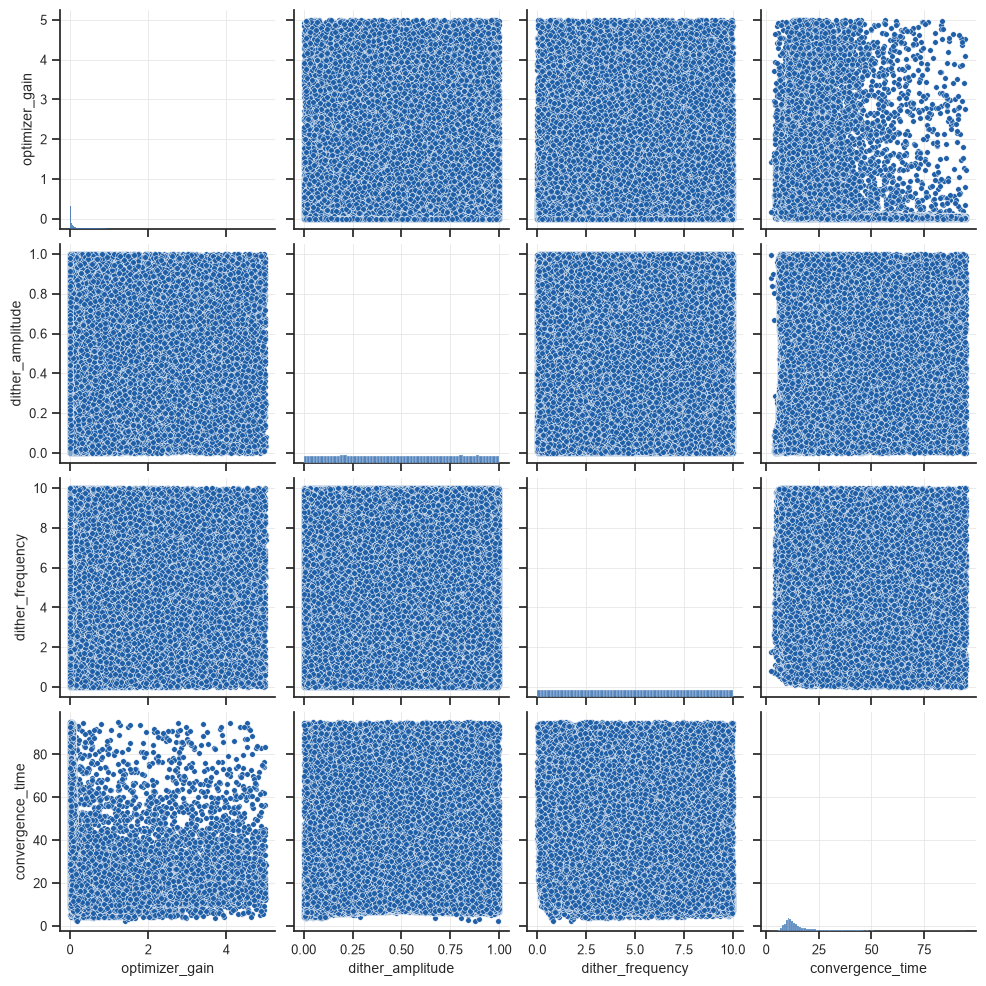

In [8]:
sns.pairplot(df,
             vars = ['optimizer_gain','dither_amplitude','dither_frequency', 'convergence_time'])
plt.show()

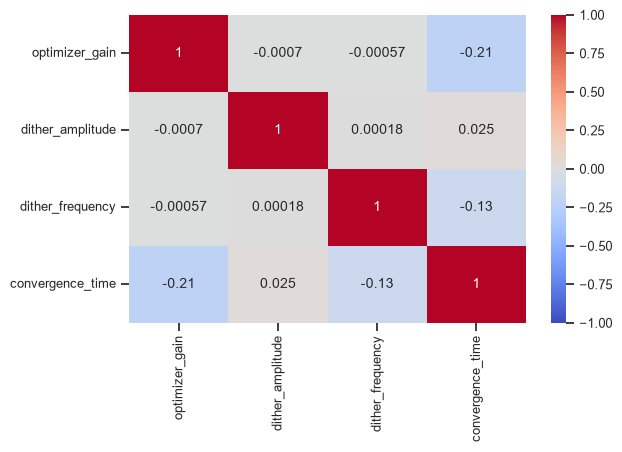

In [9]:
sns.heatmap(df.drop(columns = 'converged').corr(), annot = True, cmap = 'coolwarm', vmin = -1, vmax = 1, center = 0)
plt.show()

#### Added plots (gain on a logarithmic axis, random samples)

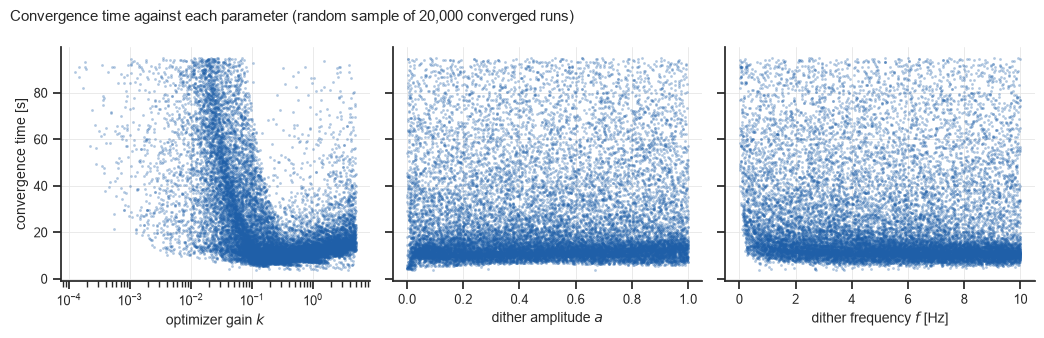

In [10]:
esc.scatter_grid(df, esc.ESC_PARAMS, 'convergence_time',
                 title='Convergence time against each parameter (random sample of 20,000 converged runs)')
plt.show()

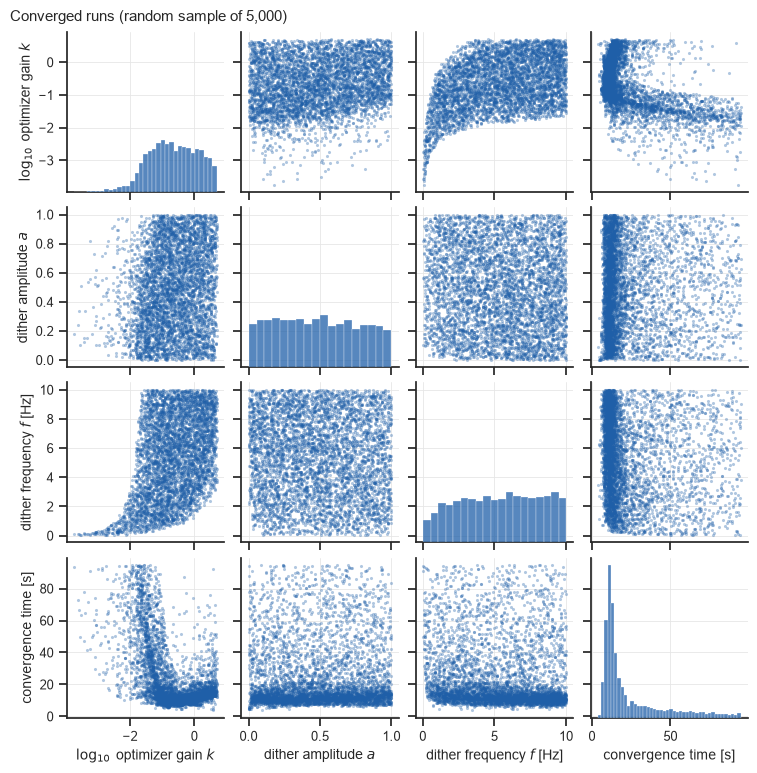

In [11]:
cols = esc.ESC_PARAMS + ['convergence_time']
esc.pair_plot(df, cols, title='Converged runs (random sample of 5,000)')
plt.show()

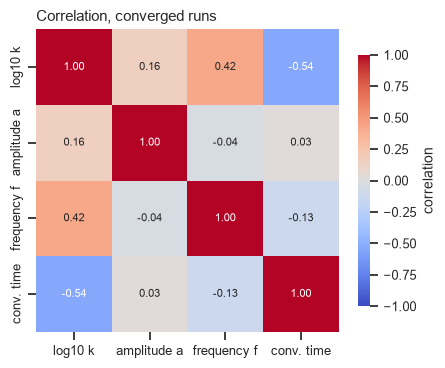

In [12]:
converged = df.dropna(subset=['convergence_time']).assign(log10_gain=lambda d: np.log10(d['optimizer_gain']))
heat_cols = ['log10_gain', 'dither_amplitude', 'dither_frequency', 'convergence_time']
esc.corr_heatmap(converged, heat_cols, title='Correlation, converged runs')
plt.show()

### Fast runs (convergence time under 10 s)

Gain and dither frequency are correlated among the converged runs, and more strongly among the fast ones:
a faster dither needs a larger gain. Section 5 explains this with the averaged convergence rate.

#### Original plots

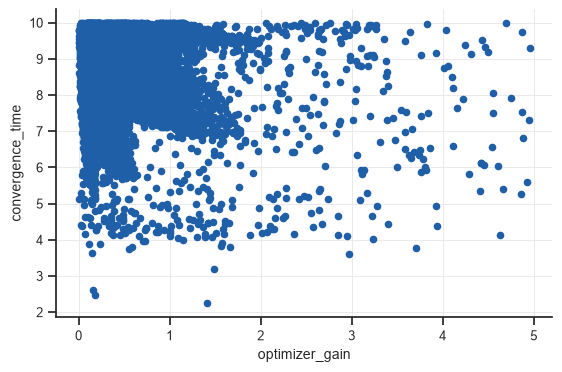

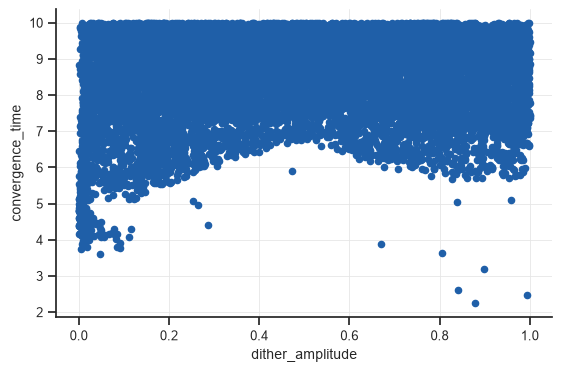

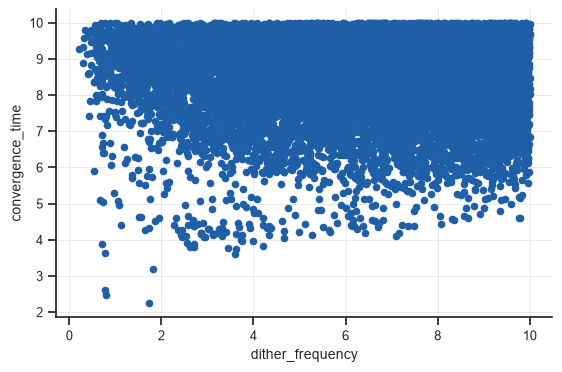

In [13]:
dfcut = df[df['convergence_time'] < 10]
for i in range (dfcut.shape[1] - 2):
    dfcut.plot(kind = 'scatter',
            x = i,
            y = 'convergence_time')
    plt.show()

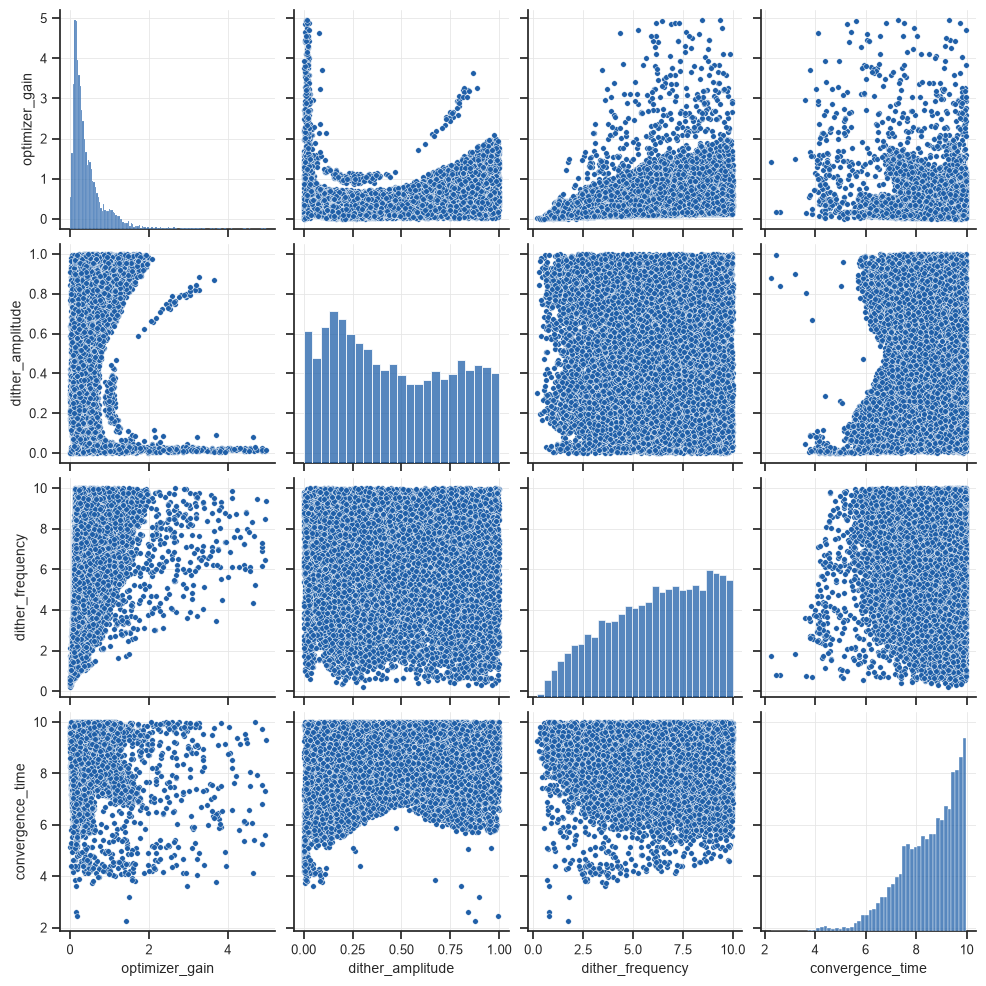

In [14]:
sns.pairplot(dfcut,
             vars = ['optimizer_gain','dither_amplitude','dither_frequency', 'convergence_time'])
plt.show()

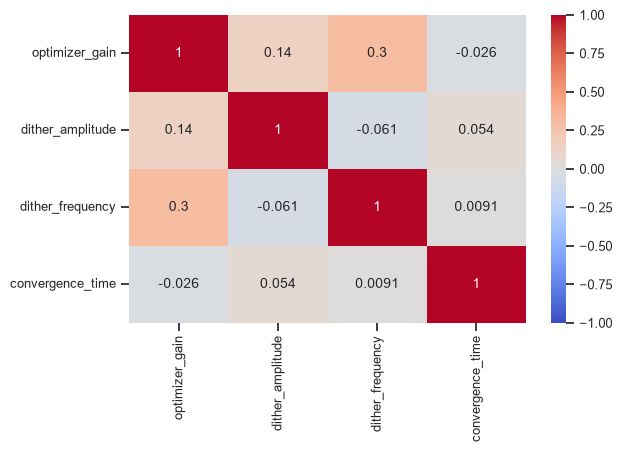

In [15]:
sns.heatmap(dfcut.drop(columns = 'converged').corr(), annot = True, cmap = 'coolwarm', vmin = -1, vmax = 1, center = 0)
plt.show()

#### Added plots (gain on a logarithmic axis, random samples)

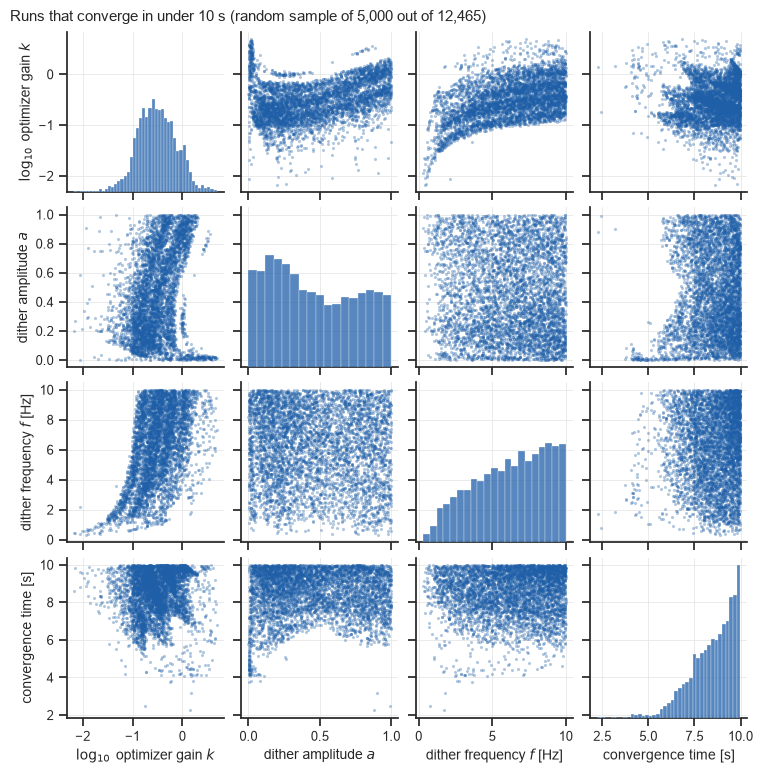

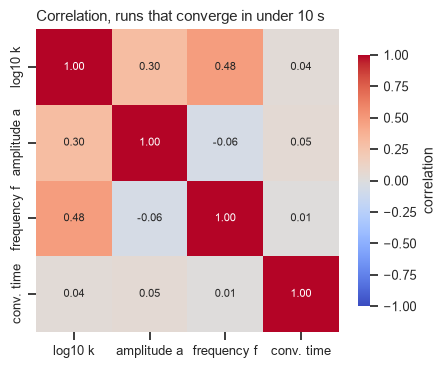

In [16]:
fast = converged[converged['convergence_time'] < 10]
esc.pair_plot(fast, cols, title=f'Runs that converge in under 10 s (random sample of 5,000 out of {len(fast):,})')
plt.show()
esc.corr_heatmap(fast, heat_cols, title='Correlation, runs that converge in under 10 s')
plt.show()

## 5. Averaged-ESC analysis

Each run is summarised by one number computed from its ESC parameters, the **averaged convergence rate**

$$\lambda_\mathrm{avg} = 2\,n_\mathrm{ref}^2\,k\,c(\omega),$$

where $c(\omega)$ is how much of the dither survives the plasma's low-pass response and the high-pass filter
(`esc.c_factor`). Averaging theory predicts $\dot{\hat r} \approx -\lambda_\mathrm{avg}(\hat r - r_\mathrm{ideal})$,
so the time to enter the 5 % band from $\hat r = 0$ is about $\ln 20/\lambda_\mathrm{avg}$.
The derivation is in the report (Section 3.2); it still has to be checked by the supervisor.

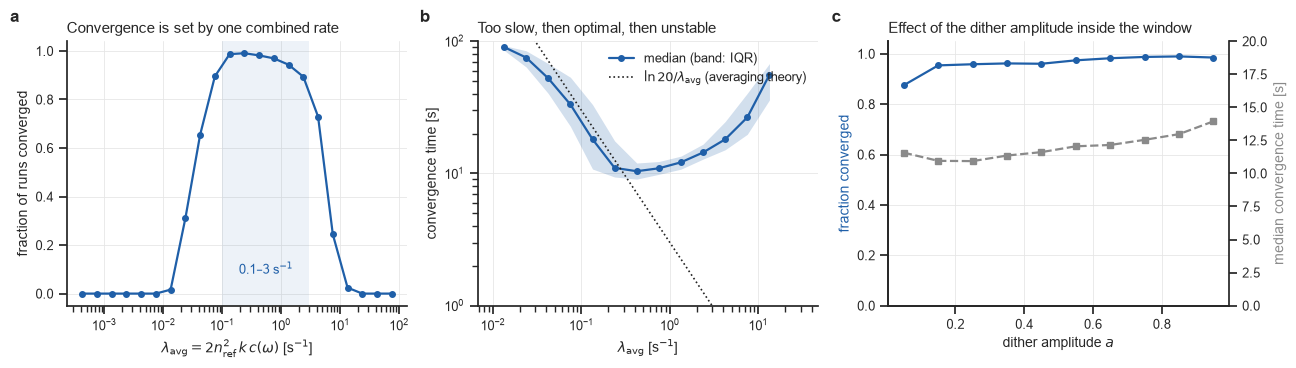

Runs with 0.1 < lam_avg < 3.0 1/s: 51,852 of 200,000; converged: 96.3%


In [17]:
fig, window = esc.convergence_vs_rate(df)
plt.show()
low, high = esc.LAM_WINDOW
print(f"Runs with {low} < lam_avg < {high} 1/s: {len(window):,} of {len(df):,}; converged: {window['converged'].mean():.1%}")

## 6. 3-D view

Interactive view of the converged runs in ESC-parameter space (drag to rotate). Only a random sample is drawn
to keep the notebook small.

#### Original plots

In [ ]:
import plotly.express as px

fig200k = px.scatter_3d(df,
                    x = 'optimizer_gain',
                    y = 'dither_amplitude',
                    z = 'dither_frequency',
                    color = 'convergence_time',
                    color_continuous_scale = 'Viridis',
                    title = '3D scatter',
                    labels = {'optimizer_gain' : 'Optimizer gain',
                              'dither_amplitude' : 'Dither amplitude',
                              'dither_frequency' : 'Dither Frequency'})
fig200k.update_traces(marker=dict(size=3))
fig200k.show()

# Exporting the plot (kept as a comment so the file is not rewritten every time the notebook runs)
# fig200k.write_html("3dscatter200k.html")

#### Added plots (random sample of 20,000 converged runs, gain on a logarithmic axis)

In [ ]:
fig = esc.scatter3d(df, 'convergence_time', sample=20000, title='Convergence time in ESC-parameter space (20,000 converged runs)')
fig.show()

## 7. Classifier: predict convergence from the parameters

Two small fully connected networks are trained to predict `converged`. The inputs are the ESC parameters and
three engineered features. The data are split 60 % / 20 % / 20 % into training, cross-validation and test sets;
the test set is kept for the final model. The **majority baseline** is the accuracy of always predicting the
more frequent class, which is the number a classifier has to beat.

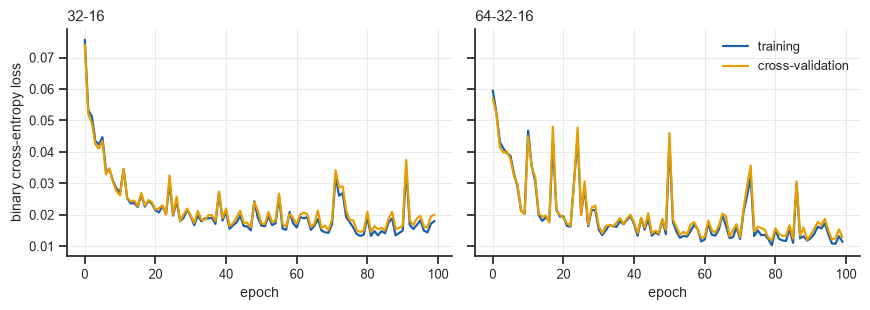

,train accuracy,CV accuracy,majority baseline (CV)
model,,,
32-16,0.993,0.992,0.63
64-32-16,0.995,0.995,0.63


In [ ]:
import torch
import esc_ml as ml

features = df[esc.ESC_PARAMS].copy()
features['log10gain'] = np.log10(df['optimizer_gain'])
features['sinfre'] = np.sin(df['dither_frequency'])
features['product'] = df['optimizer_gain'] * df['dither_amplitude'] * features['sinfre']
data = ml.split_data(features, df['converged'])

torch.manual_seed(1)   # reproducible initial weights
models = {'32-16': ml.make_model(features.shape[1], hidden=(32, 16)),
          '64-32-16': ml.make_model(features.shape[1], hidden=(64, 32, 16))}
histories = {name: ml.train_classifier(model, data['X_train'], data['y_train'], data['X_cv'], data['y_cv'],
                                       epochs=100, batch_size=1000)
             for name, model in models.items()}

esc.loss_curves(histories)
plt.show()
ml.summary_table(models, data)

Confusion matrix of the better model, and where it goes wrong: the table gives the median of each feature for
the correct predictions, the false positives (predicted to converge, did not) and the false negatives.

In [ ]:
best = max(models, key=lambda name: ml.accuracy(models[name], data['X_cv'], data['y_cv']))
ml.report(models[best], data['X_cv'], data['y_cv'], title=f'Model {best} on the cross-validation set')
ml.error_table(models[best], data['X_cv'], data['y_cv']).round(4)

Model 64-32-16 on the cross-validation set: accuracy 0.995 (majority baseline 0.629)
confusion matrix [rows: true 0/1, columns: predicted 0/1]
[[25020   160]
 [   59 14761]]
              precision    recall  f1-score   support

           0      0.998     0.994     0.996     25180
           1      0.989     0.996     0.993     14820

    accuracy                          0.995     40000
   macro avg      0.993     0.995     0.994     40000
weighted avg      0.995     0.995     0.995     40000



,correct,false negative,false positive
optimizer_gain,0.0071,0.0198,0.0318
dither_amplitude,0.4981,0.1866,0.5083
dither_frequency,5.0174,1.3703,2.9425
log10gain,-2.1494,-1.7032,-1.4978
sinfre,0.3108,0.2827,0.3642
product,0.0000,0.0001,0.0012
number of runs,39781.0000,59.0000,160.0000


## 8. Safe operating region of the ESC parameters

Where in the space of $k$, $a$, $f$ is it safe to run the ESC? The parameter space is cut into small bins and every
bin is judged by the runs around it: the maps use 100 × 100 bins (about 20 runs per bin), smoothed over about 1.5 bins
with `esc.binned_map`, so that each value is an average over roughly 280 runs:

| class | rule (per bin) |
|---|---|
| unsafe | less than 50 % of the runs converge |
| marginal | 50 to 90 % converge |
| safe | at least 90 % converge; split by the median convergence time of the converged runs into **fast** (up to 12 s), **medium** (12 to 20 s) and **slow** (more than 20 s) |

The limits (50 %, 90 %, 12 s, 20 s) are proposals and are set in one place (`SAFE`, `MARGINAL`, `FAST`, `MEDIUM` below).

The white lines are the averaged-ESC prediction of Section 5: the gain at which $\lambda_\mathrm{avg}$ = 0.1 s$^{-1}$
(dashed) and 3 s$^{-1}$ (dash-dot). Two reference sets are marked: the supervisor's starting values
($k = 3\times10^{-4}$, $a = 0.1$, $f = 0.1$ Hz) and the set tuned in the optimal-to-operate notebooks ($k = 1$, $a = 0.2$, $f = 6$ Hz).

**First view: share of runs that converge.** Left: gain against dither frequency (all amplitudes together).
Right: gain against dither amplitude (all frequencies together). The contours mark 50 % and 90 %.

200,000 runs; 100 x 100 bins with 6 to 40 runs each (median 20) before smoothing over 1.5 bins


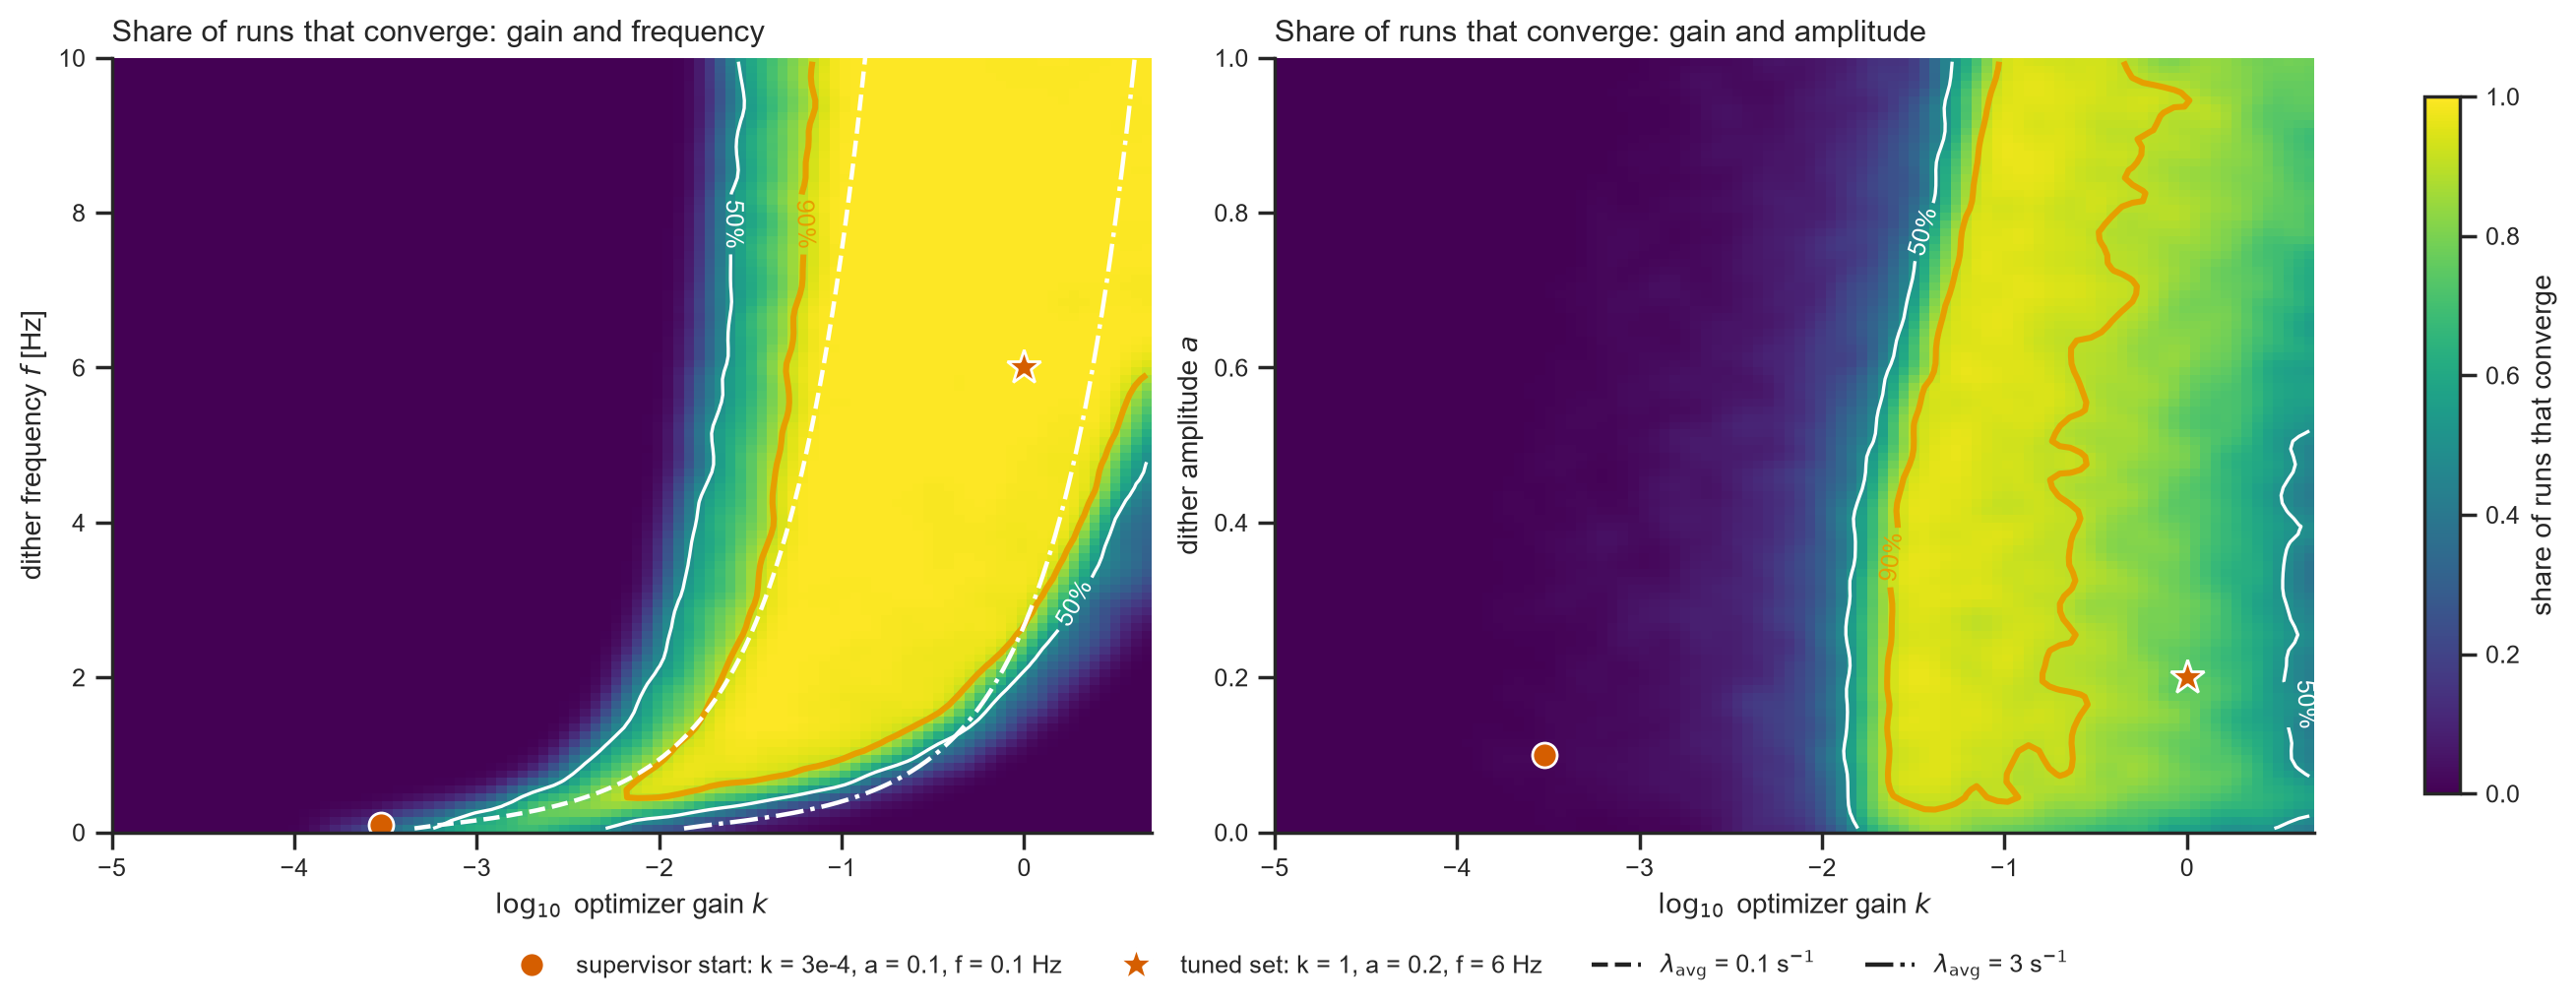

In [ ]:
from matplotlib.colors import BoundaryNorm, ListedColormap
SAFE, MARGINAL = 0.9, 0.5          # share of runs that must converge
FAST, MEDIUM = 12.0, 20.0          # median convergence time [s]
SMOOTH = 1.5                       # width of the smoothing, in bins (0: plain bins)
REFERENCES = {'supervisor start: k = 3e-4, a = 0.1, f = 0.1 Hz': (3e-4, 0.1, 0.1, 'o'),
              'tuned set: k = 1, a = 0.2, f = 6 Hz': (1.0, 0.2, 6.0, '*')}

runs = df.assign(log10_gain=np.log10(df['optimizer_gain']), converged=df['converged'].astype(float))
gain_edges = np.linspace(-5, np.log10(5), 101)      # 100 x 100 bins: about 20 runs per bin before smoothing
frequency_edges = np.linspace(0, 10, 101)
amplitude_edges = np.linspace(0, 1, 101)


def cell_map(data, x, y, x_edges, y_edges, value='converged', statistic='mean'):
    """Statistic of `value` on the (x, y) grid, smoothed over SMOOTH bins (see esc.binned_map)."""
    return esc.binned_map(data[x], data[y], data[value], x_edges, y_edges, statistic=statistic, smooth=SMOOTH)


def rate_lines(ax, color='white'):
    """Gains at which the averaged-ESC rate equals the limits of LAM_WINDOW, against the dither frequency."""
    f = np.linspace(0.05, 10, 300)
    for rate, style in zip(esc.LAM_WINDOW, ['--', '-.']):
        k = rate / (2 * esc.N_REF ** 2 * esc.c_factor(f))
        ax.plot(np.log10(k), f, color=color, linestyle=style, linewidth=1.6,
                label=f'$\\lambda_\\mathrm{{avg}}$ = {rate:g} s$^{{-1}}$')


def mark_references(ax, y='dither_frequency'):
    for label, (k, a, f, marker) in REFERENCES.items():
        ax.plot(np.log10(k), f if y == 'dither_frequency' else a, marker=marker, markersize=13 if marker == '*' else 9,
                color=esc.COLORS['bad'], markeredgecolor='white', linestyle='none', label=label)


def centres(edges):
    return 0.5 * (edges[1:] + edges[:-1])


# dpi=200: twice the usual resolution, so the maps stay sharp when the notebook shrinks the figure
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained', dpi=200)
for ax, (y, y_edges) in zip(axes, [('dither_frequency', frequency_edges), ('dither_amplitude', amplitude_edges)]):
    share = cell_map(runs, 'log10_gain', y, gain_edges, y_edges)
    image = ax.pcolormesh(gain_edges, y_edges, share.T, cmap='viridis', vmin=0, vmax=1)
    lines = ax.contour(centres(gain_edges), centres(y_edges), share.T, levels=[MARGINAL, SAFE],
                       colors=['white', esc.COLORS['fixed']], linewidths=[1.2, 2.2])
    ax.clabel(lines, fmt={MARGINAL: f'{MARGINAL:.0%}', SAFE: f'{SAFE:.0%}'}, fontsize=9)
    mark_references(ax, y)
    ax.set_xlabel(esc.LABELS['log10_gain'])
    ax.set_ylabel(esc.LABELS[y])
    ax.grid(False)
rate_lines(axes[0])
axes[0].set_ylim(0, 10)
axes[0].set_title('Share of runs that converge: gain and frequency')
axes[1].set_title('Share of runs that converge: gain and amplitude')
fig.colorbar(image, ax=axes, label='share of runs that converge', shrink=0.9)
from matplotlib.lines import Line2D
handles, labels = axes[0].get_legend_handles_labels()
handles = [Line2D([], [], color=esc.COLORS['ideal'], linestyle=h.get_linestyle()) if l.startswith('$') else h
           for h, l in zip(handles, labels)]        # the rate lines are white on the map; show them dark in the legend
fig.legend(handles, labels, loc='outside lower center', ncol=4)
plt.show()

runs_per_bin, _, _ = np.histogram2d(runs['log10_gain'], runs['dither_frequency'], bins=[gain_edges, frequency_edges])
print(f'{len(runs):,} runs; {len(gain_edges) - 1} x {len(frequency_edges) - 1} bins with {runs_per_bin.min():.0f} to '
      f'{runs_per_bin.max():.0f} runs each (median {np.median(runs_per_bin):.0f}) before smoothing over {SMOOTH} bins')

**The same two maps, one per figure** (larger, easier to read).

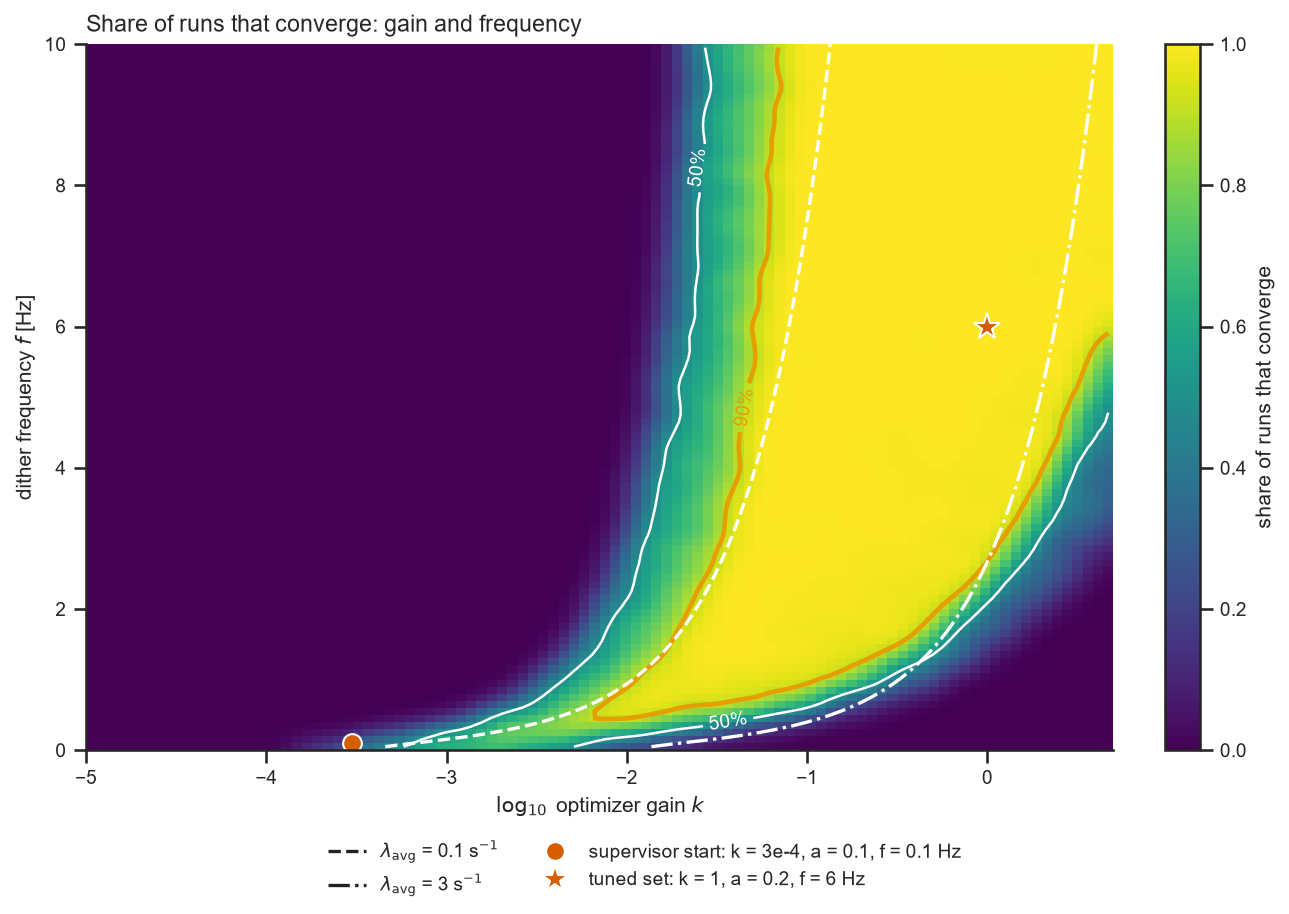

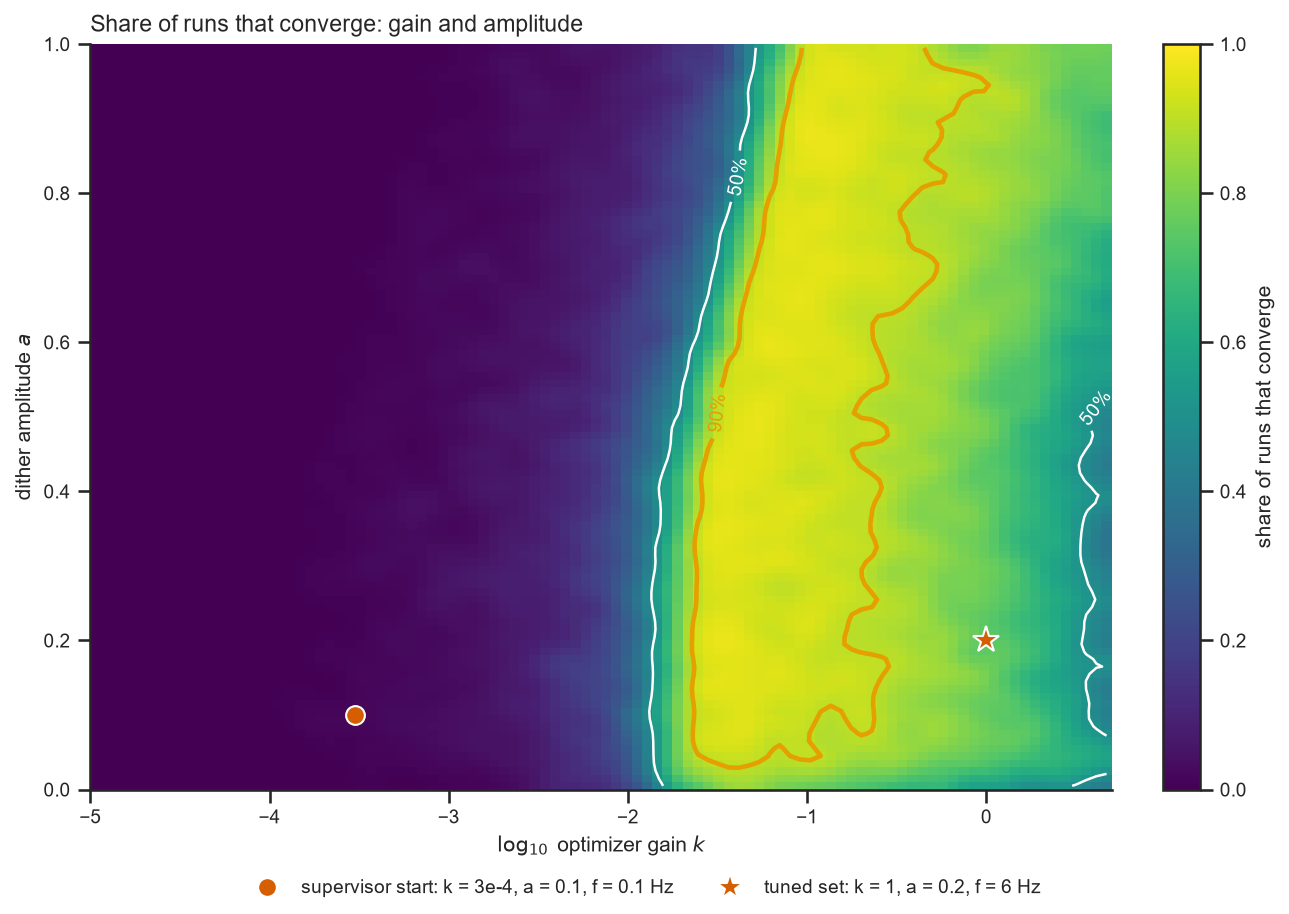

In [ ]:
from matplotlib.lines import Line2D

for y, y_edges, title in [('dither_frequency', frequency_edges, 'gain and frequency'),
                          ('dither_amplitude', amplitude_edges, 'gain and amplitude')]:
    fig, ax = plt.subplots(figsize=(8.5, 6), layout='constrained', dpi=150)
    share = cell_map(runs, 'log10_gain', y, gain_edges, y_edges)
    image = ax.pcolormesh(gain_edges, y_edges, share.T, cmap='viridis', vmin=0, vmax=1)
    lines = ax.contour(centres(gain_edges), centres(y_edges), share.T, levels=[MARGINAL, SAFE],
                       colors=['white', esc.COLORS['fixed']], linewidths=[1.2, 2.2])
    ax.clabel(lines, fmt={MARGINAL: f'{MARGINAL:.0%}', SAFE: f'{SAFE:.0%}'}, fontsize=9)
    if y == 'dither_frequency':
        rate_lines(ax)
        ax.set_ylim(0, 10)
    mark_references(ax, y)
    ax.set_xlabel(esc.LABELS['log10_gain'])
    ax.set_ylabel(esc.LABELS[y])
    ax.set_title(f'Share of runs that converge: {title}')
    ax.grid(False)
    fig.colorbar(image, ax=ax, label='share of runs that converge')
    handles, labels = ax.get_legend_handles_labels()
    handles = [Line2D([], [], color=esc.COLORS['ideal'], linestyle=h.get_linestyle()) if l.startswith('$') else h
               for h, l in zip(handles, labels)]
    fig.legend(handles, labels, loc='outside lower center', ncol=2)
    plt.show()

**Does the amplitude matter?** The gain-frequency map again, for four ranges of the dither amplitude
(coarser cells, because each range has fewer runs).

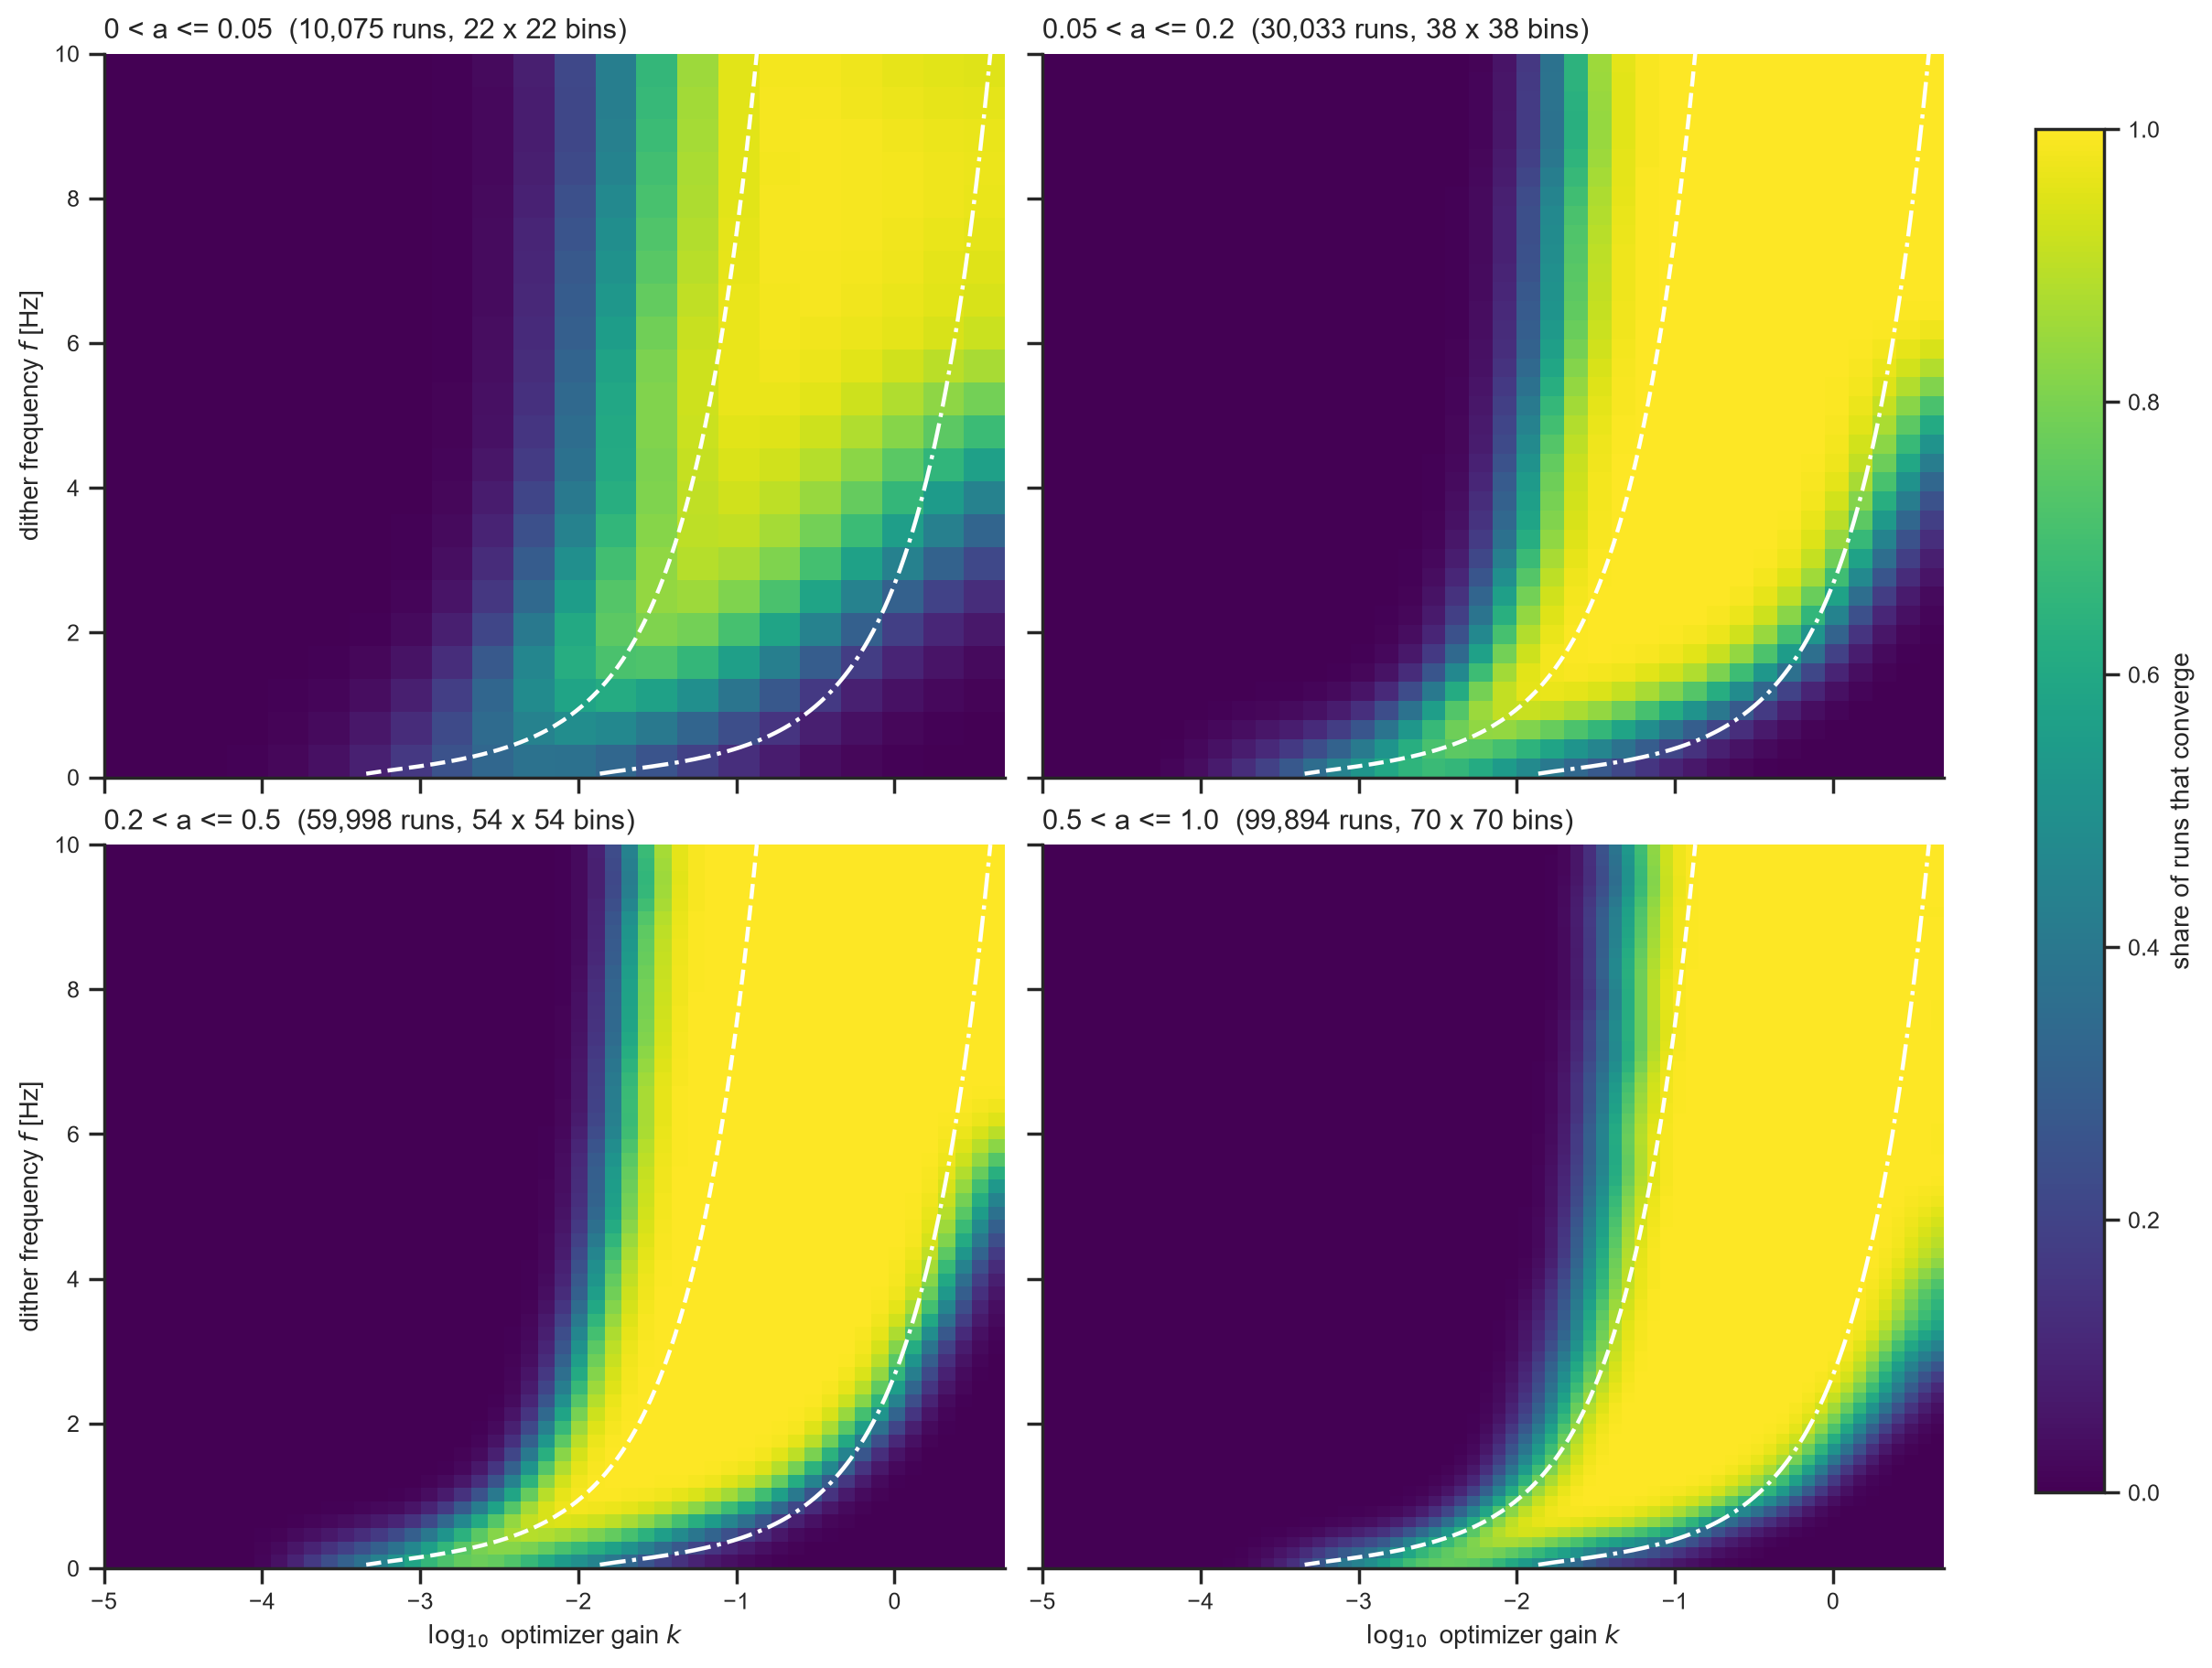

,runs,runs inside the lambda_avg window,share converged inside
amplitude range,,,
0 - 0.05,10075,2652,0.816
0.05 - 0.2,30033,7737,0.948
0.2 - 0.5,59998,15539,0.960
0.5 - 1.0,99894,25924,0.984


In [ ]:
bands = [(0, 0.05), (0.05, 0.2), (0.2, 0.5), (0.5, 1.0)]


def band_edges(n_runs):
    """Grid for a subset of the runs: about 20 runs per bin before smoothing (esc.bins_for)."""
    n = esc.bins_for(n_runs)
    return np.linspace(-5, np.log10(5), n + 1), np.linspace(0, 10, n + 1)


fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True, layout='constrained', dpi=200)
rows = []
for ax, (low, high) in zip(axes.ravel(), bands):
    band = runs[(runs['dither_amplitude'] > low) & (runs['dither_amplitude'] <= high)]
    band_gain, band_frequency = band_edges(len(band))
    share = cell_map(band, 'log10_gain', 'dither_frequency', band_gain, band_frequency)
    image = ax.pcolormesh(band_gain, band_frequency, share.T, cmap='viridis', vmin=0, vmax=1)
    rate_lines(ax)
    ax.set_ylim(0, 10)
    ax.set_title(f'{low} < a <= {high}  ({len(band):,} runs, {len(band_gain) - 1} x {len(band_gain) - 1} bins)')
    ax.grid(False)
    rate = pd.Series(esc.lam_avg(band['optimizer_gain'], band['dither_frequency']), index=band.index)
    inside = band[rate.between(*esc.LAM_WINDOW)]
    rows.append({'amplitude range': f'{low} - {high}', 'runs': len(band),
                 'runs inside the lambda_avg window': len(inside), 'share converged inside': inside['converged'].mean()})
for ax in axes[1]:
    ax.set_xlabel(esc.LABELS['log10_gain'])
for ax in axes[:, 0]:
    ax.set_ylabel(esc.LABELS['dither_frequency'])
fig.colorbar(image, ax=axes, label='share of runs that converge', shrink=0.9)
plt.show()
pd.DataFrame(rows).set_index('amplitude range').round(3)

**The same four amplitude ranges, one per figure.**

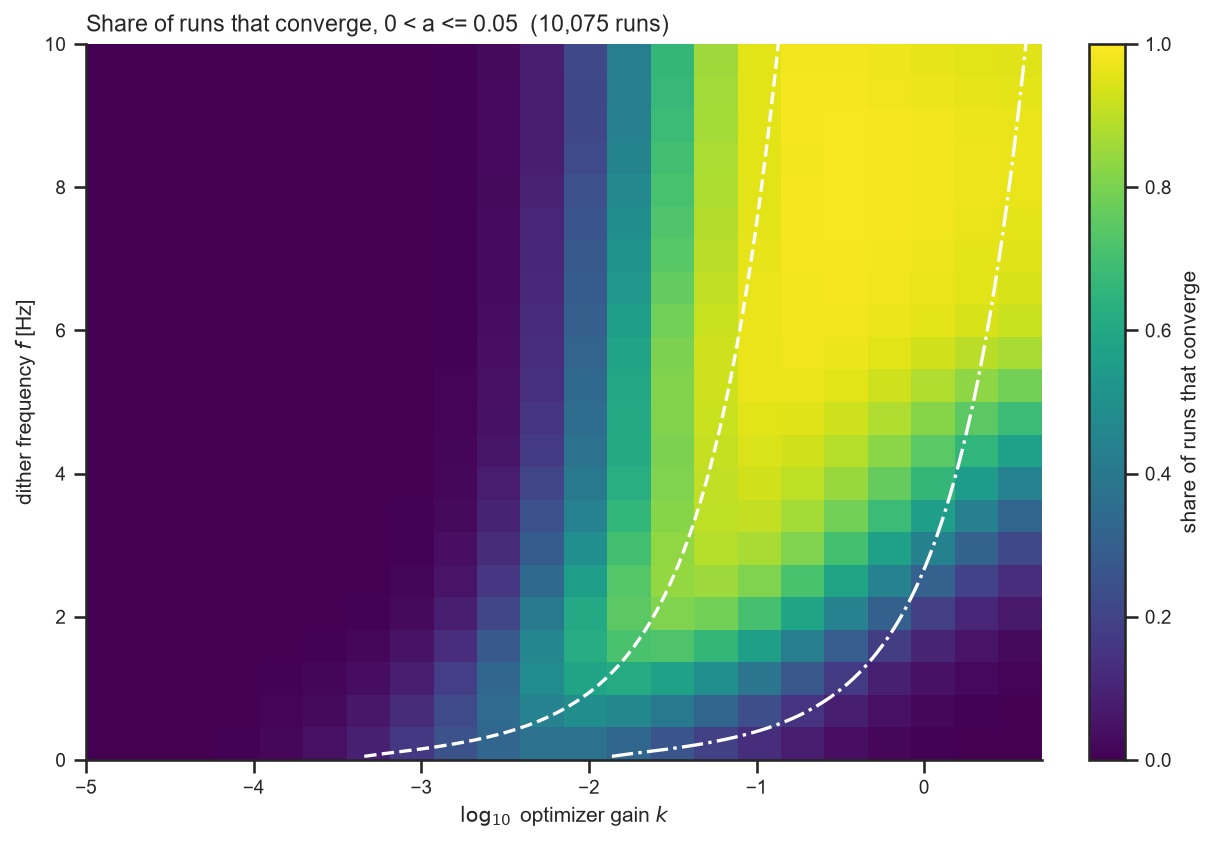

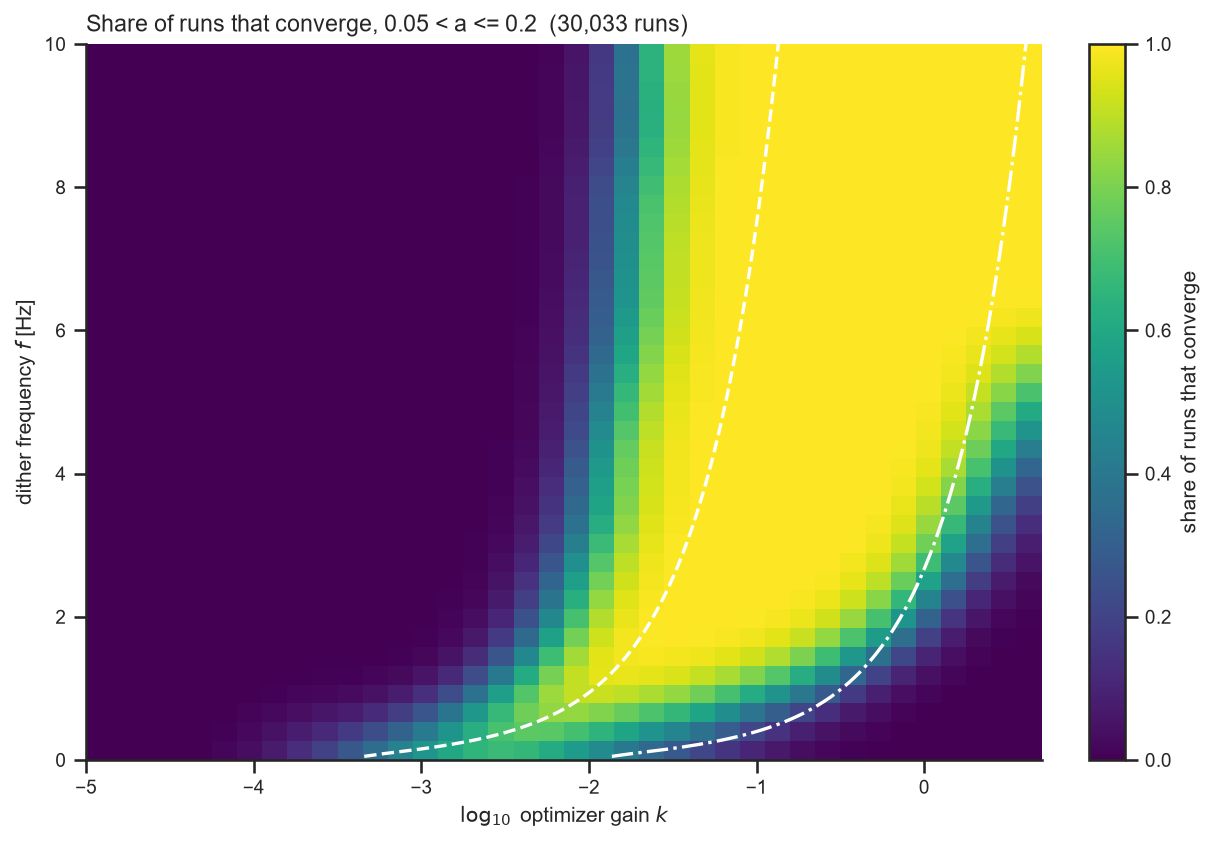

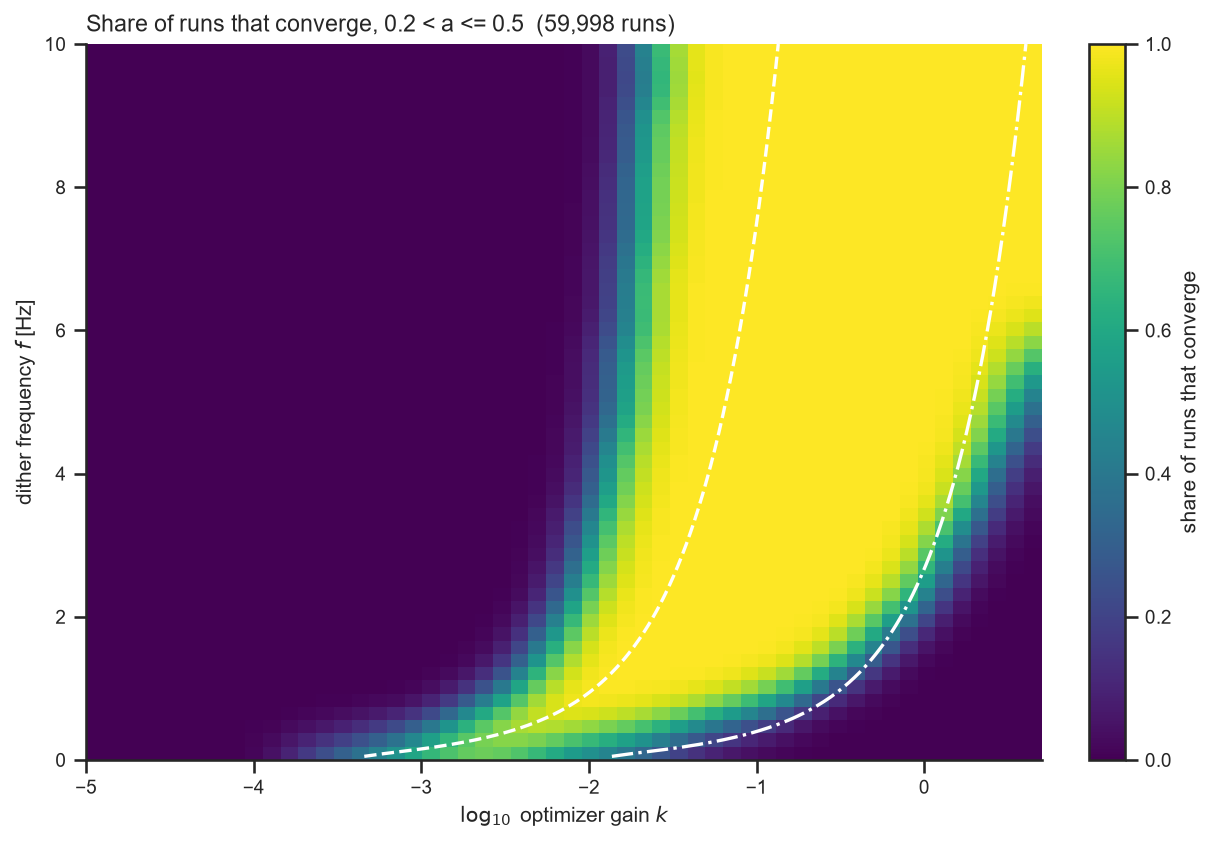

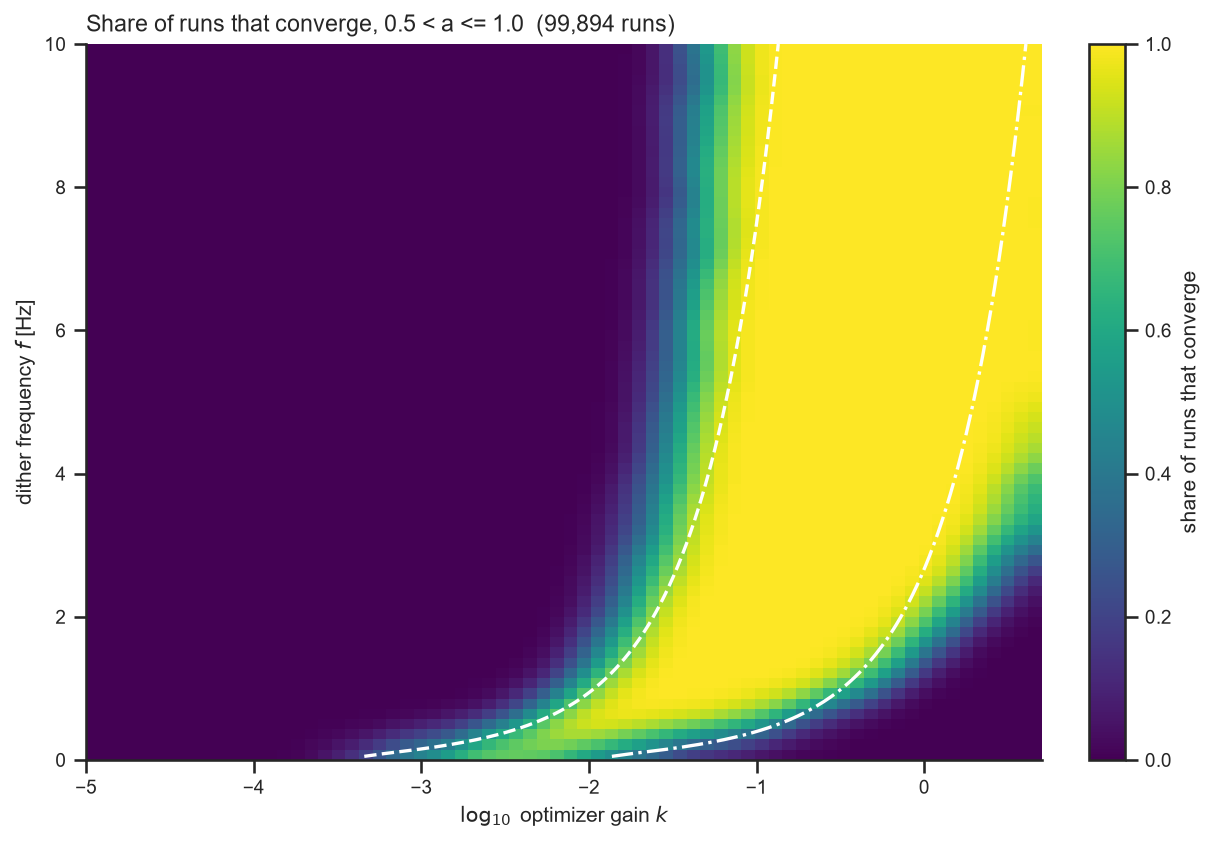

In [ ]:
for low, high in bands:
    band = runs[(runs['dither_amplitude'] > low) & (runs['dither_amplitude'] <= high)]
    band_gain, band_frequency = band_edges(len(band))
    share = cell_map(band, 'log10_gain', 'dither_frequency', band_gain, band_frequency)
    fig, ax = plt.subplots(figsize=(8, 5.5), layout='constrained', dpi=150)
    image = ax.pcolormesh(band_gain, band_frequency, share.T, cmap='viridis', vmin=0, vmax=1)
    rate_lines(ax)
    ax.set_ylim(0, 10)
    ax.set_xlabel(esc.LABELS['log10_gain'])
    ax.set_ylabel(esc.LABELS['dither_frequency'])
    ax.set_title(f'Share of runs that converge, {low} < a <= {high}  ({len(band):,} runs)')
    ax.grid(False)
    fig.colorbar(image, ax=ax, label='share of runs that converge')
    plt.show()

**Speed and the operating chart.** Left: median convergence time of the converged runs. Right: every cell of the
gain-frequency plane classified as in the table at the top of this section. Runs with $a < 0.1$ are left out of both
maps, because very small amplitudes are less reliable (previous table); for $a \ge 0.1$ the amplitude hardly matters.

median convergence time in the safe bins: 9.3 to 37.4 s (quartiles 10.7, 13.1, 17.6 s)


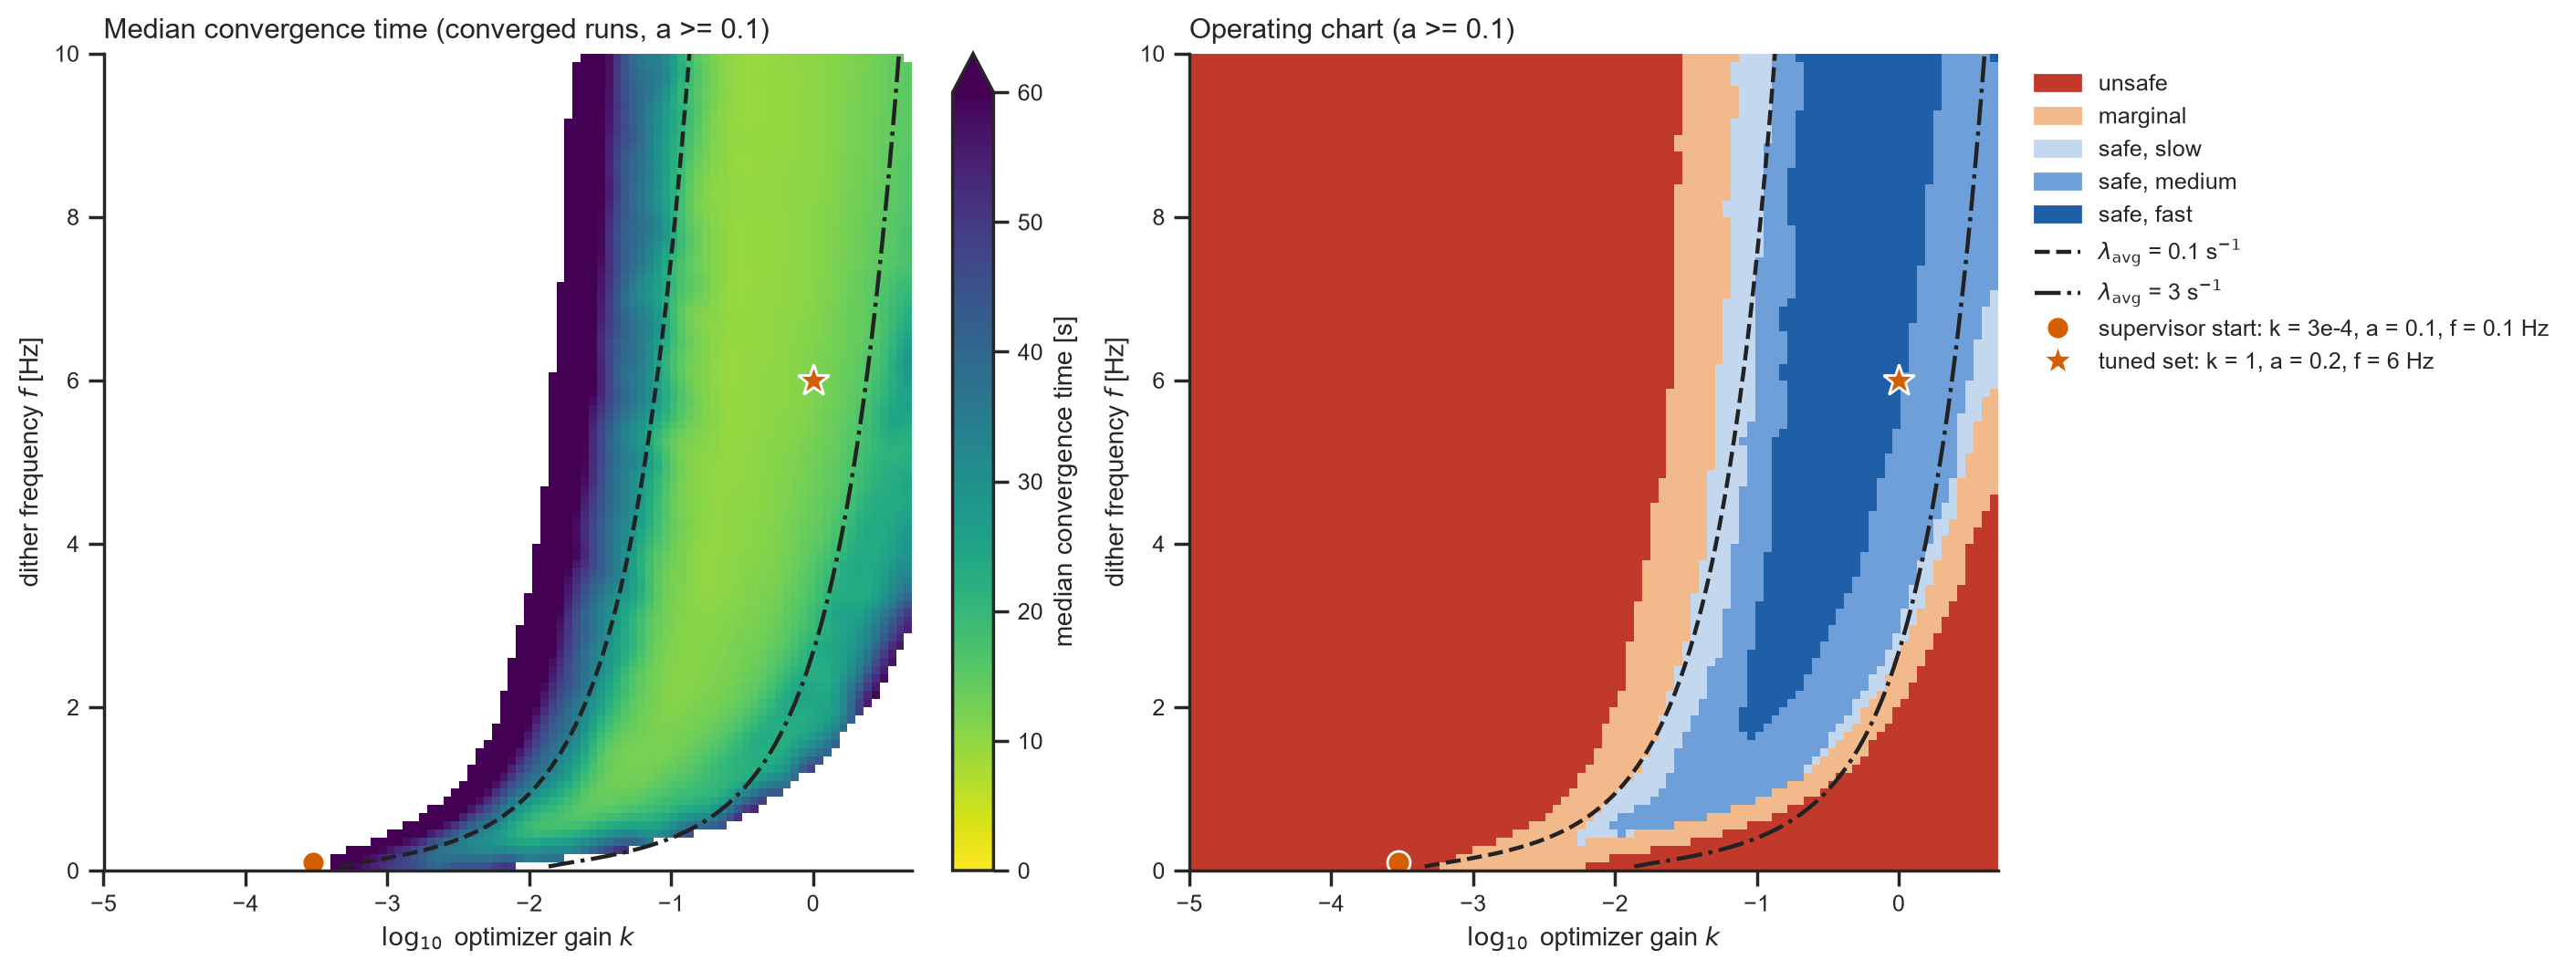

,bins,share of the gain-frequency plane
unsafe,6248,0.625
marginal,927,0.093
"safe, slow",510,0.051
"safe, medium",1187,0.119
"safe, fast",1128,0.113


In [ ]:
CLASSES = ['unsafe', 'marginal', 'safe, slow', 'safe, medium', 'safe, fast']
CLASS_COLORS = ['#c0392b', '#f2b98a', '#c3d7ef', '#6f9fd8', '#1f5fa8']

usable = runs[runs['dither_amplitude'] >= 0.1]
share = cell_map(usable, 'log10_gain', 'dither_frequency', gain_edges, frequency_edges)
median_time = cell_map(usable[usable['converged'] == 1], 'log10_gain', 'dither_frequency', gain_edges, frequency_edges,
                       value='convergence_time', statistic='median')
classes = np.select([share < MARGINAL, share < SAFE, median_time > MEDIUM, median_time > FAST], [0, 1, 2, 3], default=4).astype(float)
classes[np.isnan(share)] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout='constrained', dpi=200)
image = axes[0].pcolormesh(gain_edges, frequency_edges, median_time.T, cmap='viridis_r', vmin=0, vmax=60)
fig.colorbar(image, ax=axes[0], label='median convergence time [s]', extend='max')
axes[0].set_title('Median convergence time (converged runs, a >= 0.1)')
axes[1].pcolormesh(gain_edges, frequency_edges, classes.T, cmap=ListedColormap(CLASS_COLORS),
                   norm=BoundaryNorm(np.arange(-0.5, len(CLASSES)), len(CLASSES)))
axes[1].set_title('Operating chart (a >= 0.1)')
for ax in axes:
    rate_lines(ax, color=esc.COLORS['ideal'])
    mark_references(ax)
    ax.set_xlabel(esc.LABELS['log10_gain'])
    ax.set_ylabel(esc.LABELS['dither_frequency'])
    ax.set_ylim(0, 10)
    ax.grid(False)
class_handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in CLASS_COLORS]
line_handles, line_labels = axes[1].get_legend_handles_labels()
axes[1].legend(class_handles + line_handles, CLASSES + line_labels, loc='upper left', bbox_to_anchor=(1.02, 1.0))
plt.show()

counts = pd.Series(classes[~np.isnan(classes)]).map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES)
chart_table = pd.DataFrame({'bins': counts, 'share of the gain-frequency plane': counts / counts.sum()})
safe_times = median_time[share >= SAFE]
print(f'median convergence time in the safe bins: {np.nanmin(safe_times):.1f} to {np.nanmax(safe_times):.1f} s '
      f'(quartiles {np.nanpercentile(safe_times, 25):.1f}, {np.nanpercentile(safe_times, 50):.1f}, {np.nanpercentile(safe_times, 75):.1f} s)')
chart_table.round(3)

**The same two maps, one per figure.**

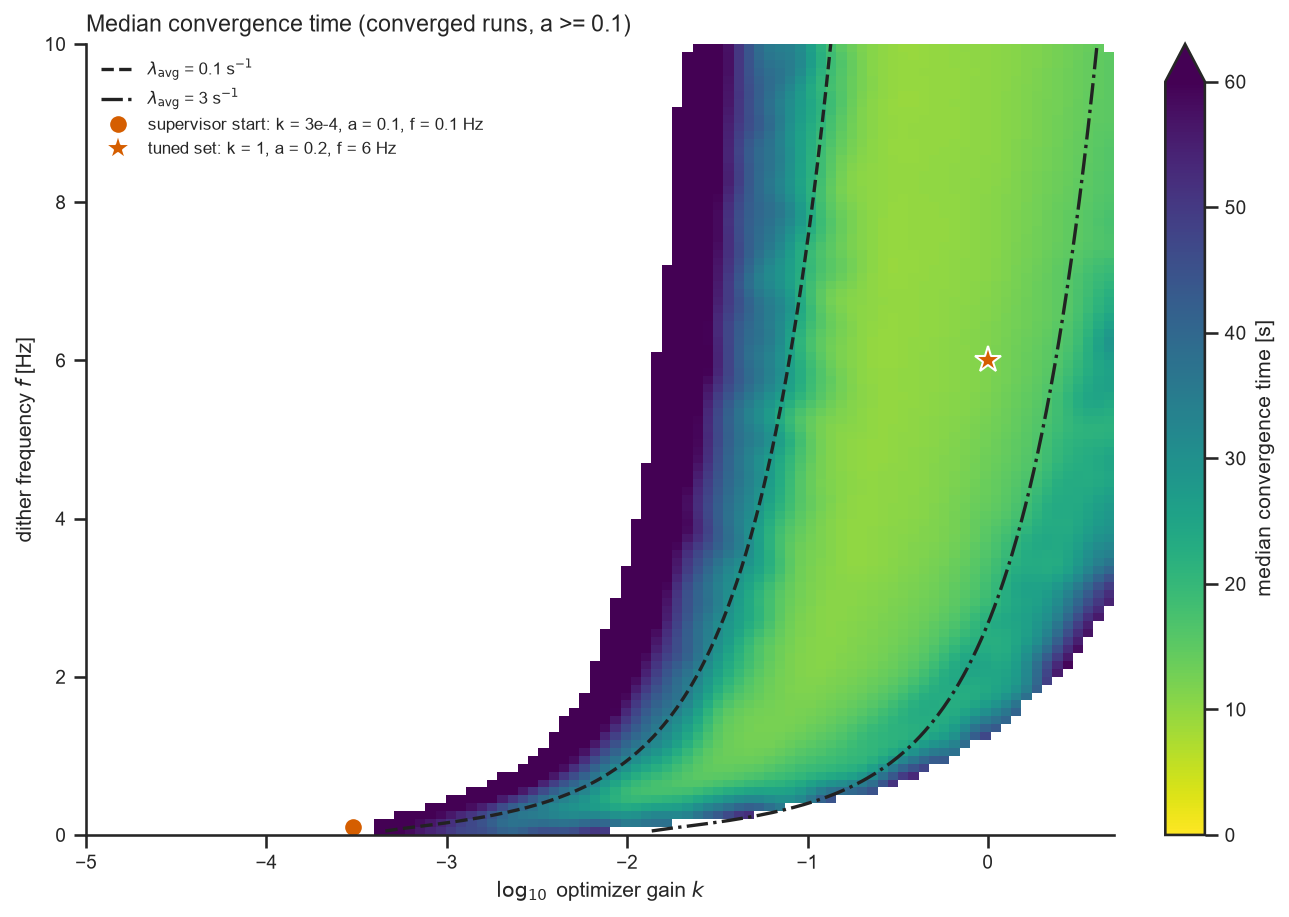

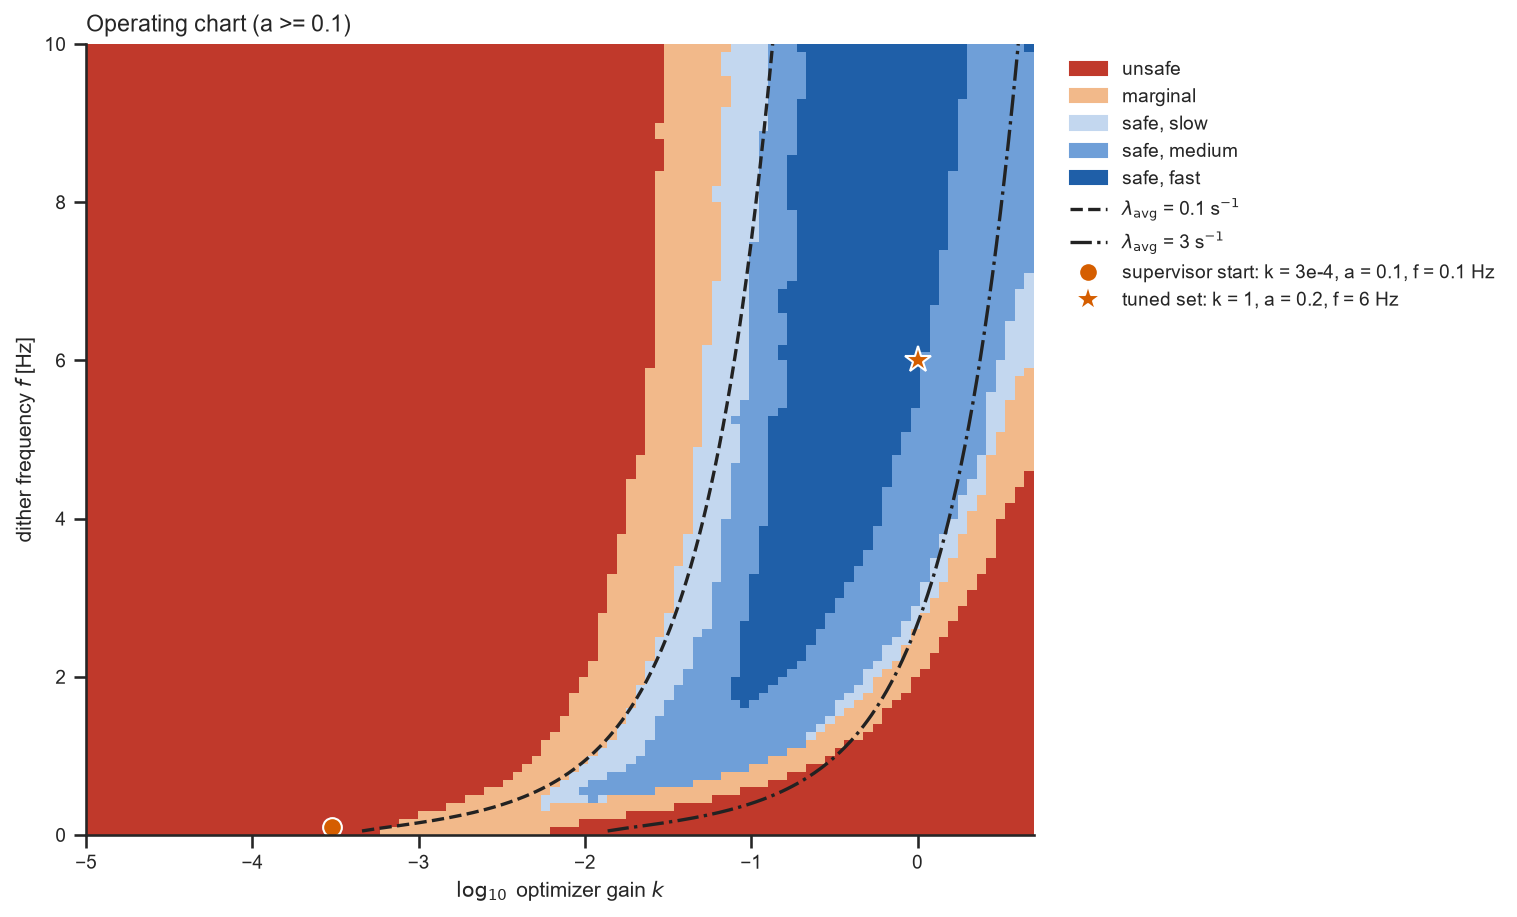

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 6), layout='constrained', dpi=150)
image = ax.pcolormesh(gain_edges, frequency_edges, median_time.T, cmap='viridis_r', vmin=0, vmax=60)
fig.colorbar(image, ax=ax, label='median convergence time [s]', extend='max')
rate_lines(ax, color=esc.COLORS['ideal'])
mark_references(ax)
ax.set_xlabel(esc.LABELS['log10_gain'])
ax.set_ylabel(esc.LABELS['dither_frequency'])
ax.set_ylim(0, 10)
ax.set_title('Median convergence time (converged runs, a >= 0.1)')
ax.grid(False)
ax.legend(loc='upper left', fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained', dpi=150)
ax.pcolormesh(gain_edges, frequency_edges, classes.T, cmap=ListedColormap(CLASS_COLORS),
              norm=BoundaryNorm(np.arange(-0.5, len(CLASSES)), len(CLASSES)))
rate_lines(ax, color=esc.COLORS['ideal'])
mark_references(ax)
ax.set_xlabel(esc.LABELS['log10_gain'])
ax.set_ylabel(esc.LABELS['dither_frequency'])
ax.set_ylim(0, 10)
ax.set_title('Operating chart (a >= 0.1)')
ax.grid(False)
line_handles, line_labels = ax.get_legend_handles_labels()
ax.legend([plt.Rectangle((0, 0), 1, 1, color=color) for color in CLASS_COLORS] + line_handles, CLASSES + line_labels,
          loc='upper left', bbox_to_anchor=(1.02, 1.0))
plt.show()

**Checks behind the notes below.** The runs near the two reference sets, and the runs at high dither frequency
that the averaged rate predicts to be too slow.

In [ ]:
from IPython.display import display

rows = []
for label, (k, a, f, marker) in REFERENCES.items():
    near = runs[(runs['log10_gain'] - np.log10(k)).abs().lt(0.15) & (runs['dither_frequency'] - f).abs().lt(0.4)]
    rows.append({'reference': label, 'runs nearby (|log10 k| < 0.15, |f| < 0.4 Hz)': len(near),
                 'share converged': near['converged'].mean(), 'median convergence time [s]': near['convergence_time'].median()})
display(pd.DataFrame(rows).set_index('reference').round(3))

rates = pd.Series(esc.lam_avg(runs['optimizer_gain'], runs['dither_frequency']), index=runs.index)
inside = rates.between(*esc.LAM_WINDOW)
print(f'inside the lambda_avg window: {inside.sum():,} runs, {runs.loc[inside, "converged"].mean():.1%} converge; '
      f'outside: {runs.loc[~inside, "converged"].mean():.1%}')
slow_prediction = (rates < esc.LAM_WINDOW[0]) & (runs['dither_frequency'] > 3) & (runs['optimizer_gain'] > 0.02)
print(f'f > 3 Hz, k > 0.02 but lambda_avg < {esc.LAM_WINDOW[0]}: {slow_prediction.sum():,} runs, '
      f'{runs.loc[slow_prediction, "converged"].mean():.1%} converge, median time {runs.loc[slow_prediction, "convergence_time"].median():.1f} s '
      f'(averaged prediction ln(20)/lambda_avg: median {np.median(np.log(20) / rates[slow_prediction]):.1f} s)')

inside the lambda_avg window: 51,852 runs, 96.3% converge; outside: 16.1%
f > 3 Hz, k > 0.02 but lambda_avg < 0.1: 15,088 runs, 76.7% converge, median time 43.5 s (averaged prediction ln(20)/lambda_avg: median 60.6 s)


,"runs nearby (|log10 k| < 0.15, |f| < 0.4 Hz)",share converged,median convergence time [s]
reference,,,
"supervisor start: k = 3e-4, a = 0.1, f = 0.1 Hz",495,0.139,71.15
"tuned set: k = 1, a = 0.2, f = 6 Hz",872,0.999,11.51


**What the safe region looks like** (numbers printed above)

- **The gain and the dither frequency decide; the amplitude hardly does.** The safe region is a curved band in the
  gain-frequency plane. A faster dither needs a larger gain. Along the amplitude axis the band barely changes for
  $a \ge 0.05$; only very small amplitudes ($a \le 0.05$) make the edges ragged (82 % of the runs inside the
  $\lambda_\mathrm{avg}$ window converge there, against 95 to 98 % for larger amplitudes).
- **The averaged-ESC band describes the region well at low frequency.** Inside the band 96.3 % of the runs converge,
  outside it 16.1 %. Above about 2 Hz the left edge of the safe region becomes vertical near $k \approx 0.02$: there
  the averaged rate is too pessimistic. Of the runs with $f > 3$ Hz and $k > 0.02$ that the averaged rate places below
  the band, 76.7 % converge, with a median time of 43.5 s instead of the predicted 60.6 s.
- **Unsafe on two sides.** Too small a gain is too slow to converge within 100 s. Too large a gain (right of the
  dash-dot line) does not converge either at low dither frequency; overshoot of $\hat r$ is the likely cause, but
  that was not checked here.
- **28.3 % of the gain-frequency plane is safe** for $a \ge 0.1$ (11.3 % fast, 11.9 % medium, 5.1 % slow; the plane
  runs from $k = 10^{-5}$ to 5 and $f$ = 0 to 10 Hz). Even the fastest safe bins need a median of 9 to 11 s, partly
  because every run starts at 25 % density with $\hat r = 0$.
- **The supervisor's starting values lie at the edge**: only 13.9 % of the nearby runs converge (median 71 s).
  The tuned set ($k = 1$, $a = 0.2$, $f = 6$ Hz) lies in the safe band: 99.9 % of the nearby runs converge (median 11.5 s).

**Limits.** Convergence is judged on $\hat r$ (within 5 % of $r_\mathrm{ideal}$ for 5 s), for the constant plant,
without measurement noise. The class limits (50 %, 90 %, 12 s, 20 s) and the smoothing (1.5 bins) are proposals.

## Notes

- **How the parameter ranges were chosen.** The ranges were widened step by step, because fast convergence kept
  appearing at the edge of each range: first gain $10^{-3}$–$0.1$, amplitude $0.01$–$0.5$, frequency $0.4$–$0.8$ Hz;
  then gain $10^{-4}$–$0.15$, amplitude up to 1, frequency $0.1$–$1.5$ Hz; finally the ranges used here.
  Those earlier sweeps were generated with a script that swapped $n_D$ and $n_T$, so they were removed from the
  repository (they are still in the git history).
- The useful lower limit of the gain depends on the run length (100 s here): a slower loop simply does not
  arrive in time.
- Large dither amplitudes and high dither frequencies still give short convergence times, provided the gain
  is raised with the frequency.
- A few isolated parameter sets converge where their neighbours do not.
- `sinfre` and `product` were engineered by trial; the averaged rate $\lambda_\mathrm{avg}$ of Section 5 is a
  physically motivated feature to try next.